<a href="https://colab.research.google.com/github/amavi-e/A-TinyML-Powered-Wearable-Navigation-Aid-for-the-Visually-Impaired/blob/preprocessing/irp_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FYP dataset v3 - EDA, preprocessing and final dataset
TinyML wearable navigation aid. One notebook, three parts. Use a **CPU runtime** (no GPU needed). Run the cells top to bottom.

**Part A - Setup (cells 0-4):** settings, class schema, helpers, loaders. Run these first in every session.

**Part B - EDA (cells 5a-6):** one cell per dataset, then a combined view (duplicates across datasets, photos available per class).

**Part C - Preprocessing (cells 7-10):** leak-free split, build the final dataset (1000 images per class), save to Drive, verify.

If the runtime disconnects: run Part A again, then continue. Reading results are cached on Drive (`FYP/cache_v3`) and finished class folders are skipped when you re-run cell 8.

## Part A - Setup

In [ ]:
# CELL 0 - SETUP: imports, Drive, folders and global settings. Run this first in every session.
import os, re, json, time, random, shutil, hashlib, csv, math, subprocess   # standard-library tools used below
import xml.etree.ElementTree as ET   # parser for Pascal-VOC xml label files
from pathlib import Path   # object-style file paths
from collections import defaultdict, Counter, deque   # grouped dicts, counters and queues
from concurrent.futures import ThreadPoolExecutor   # runs file reads in parallel threads
import numpy as np, cv2   # arrays and OpenCV for image work
from PIL import Image   # reads an image header (its size) without decoding the whole image
import matplotlib.pyplot as plt   # charts and image grids

DRIVE = '/content/drive/MyDrive'   # where Google Drive appears inside Colab
try:   # only Colab has the google.colab package
    from google.colab import drive   # Colab's helper for mounting Drive
    if not os.path.ismount('/content/drive'):   # mount only when Drive is not mounted yet
        drive.mount('/content/drive')   # asks you to allow Drive access
except ImportError:   # we are not running inside Colab
    pass   # nothing to mount

DS = f'{DRIVE}/FYP/dataset'   # folder that holds all the raw datasets
CACHE = f'{DRIVE}/FYP/cache_v3'   # cached label/size reads on Drive (survives a runtime reset)
LOCAL_JSON = '/content/outdoor_json'   # local copy of the 3 outdoor annotation files (Drive reads fail often)
EDA_DIR = '/content/eda_v3'   # EDA pictures are saved here
FINAL_LOCAL = '/content/final_dataset'   # the final dataset is BUILT here (fast local disk)
FINAL_DRIVE = f'{DRIVE}/FYP/final_dataset'   # ...then copied here as a normal folder you can open
FINAL_TAR = f'{DRIVE}/FYP/final_dataset.tar'   # ...and archived here as ONE file (best for training)
for d in (CACHE, LOCAL_JSON, EDA_DIR):   # make sure each working folder exists
    os.makedirs(d, exist_ok=True)   # create it if missing

SIZE = 320   # every final image is a 320x320 square
SEED = 42   # fixed random seed so every run gives the same dataset
MIN_AREA = 0.003   # a box smaller than 0.3% of the final frame is dropped (too tiny to see)
MAX_AREA = 0.95   # a box bigger than 95% of the final frame is dropped (it fills the whole picture)
MIN_SIDE = 0.02   # a box thinner than 2% of the frame (either side) is dropped
BG_MIN_AREA = 0.02   # tree/bushes lose "largest box" status if another class covers at least 2% of the frame
PHASH_T = 4   # two images whose 64-bit hashes differ in <= 4 bits are treated as the same photo
TOTAL_PER_CLASS = 1000   # images per class in the final dataset (all splits together)
SPLIT_FRAC = {'train': 0.8, 'val': 0.1, 'test': 0.1}   # share of each class that goes to each split
QUOTA = {s: round(TOTAL_PER_CLASS * f) for s, f in SPLIT_FRAC.items()}   # images per class per split (800/100/100)
QUAL = dict(min_side=64, min_mean=15, max_mean=240, min_std=8)   # image quality limits (size, brightness, contrast)
CW_BLOCK = 25   # crosswalk frames numbered within the same block of 25 count as one scene
DOOR_BLOCK = 10   # door photos numbered within the same block of 10 count as one scene
DOOR_MASK_VALUE = 1   # pixel value that means "door or door frame" in the Door Detection masks
TM_MIN = 0.90   # minimum template-match score to trust a recovered door box
WORKERS = 4   # parallel threads for reading files
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}   # file extensions treated as images
print('Quota per class per split:', QUOTA, '| total per class:', sum(QUOTA.values()))   # confirm the settings


Mounted at /content/drive
Quota per class per split: {'train': 800, 'val': 100, 'test': 100} | total per class: 1000


In [ ]:
# CELL 1 - CLASS SCHEMA: the final classes, which raw classes merge into them, and the name mappings.
CLASS_LIST = [   # the final classes, in id order (id = position in this list)
    'person', 'bicycle', 'car', 'motorcycle', 'bus', 'truck', 'traffic light', 'stop sign',   # road users and street furniture
    'fire hydrant', 'bench', 'stairs', 'chair', 'couch', 'table', 'door', 'bed', 'toilet',   # obstacles and indoor items
    'sink', 'tv', 'dog', 'cat', 'bird', 'animal', 'object', 'crosswalk', 'vegetation', 'pothole']   # animals, groups and ground hazards
CLASS_ID = {n: i for i, n in enumerate(CLASS_LIST)}   # class name -> id
NC = len(CLASS_LIST)   # number of final classes
MEMBERS = {   # merged classes -> the raw classes inside them (balanced equally inside the class)
    'vegetation': ['tree', 'bushes', 'potted plant'],   # all plants
    'object': ['backpack', 'handbag', 'umbrella', 'laptop', 'refrigerator', 'oven', 'microwave',   # carried / household items
               'clock', 'vase', 'suitcase', 'traffic cone'],   # ...plus suitcase and traffic cone
    'animal': ['horse', 'cow', 'sheep', 'elephant', 'bear', 'zebra', 'giraffe'],   # large animals
    'door': ['door', 'elevator'],   # doors and elevator doors
}   # end of the merged-class table
MEMBER_LIST = [m for c in CLASS_LIST for m in MEMBERS.get(c, [c])]   # every member, grouped by class (single-member classes use their own name)
MEMBER_ID = {m: i for i, m in enumerate(MEMBER_LIST)}   # member name -> member id
MEMBER_CLASS = {m: CLASS_ID[c] for c in CLASS_LIST for m in MEMBERS.get(c, [c])}   # member name -> final class id
BACKGROUND_MEMBERS = {'tree', 'bushes'}   # usually scenery, so they rarely decide the label of a picture
COCO_ALIAS = {'dining table': 'table'}   # COCO names that differ from our member names
OUTDOOR_ALIAS = {   # outdoor-set names (after lower-casing and '_' -> ' ') that differ from our member names
    'scooter': 'motorcycle', 'green light': 'traffic light',   # scooters count as motorcycles; coloured lights are traffic lights
    'red light': 'traffic light', 'yellow light': 'traffic light'}   # (the other two light colours)
EXTRA_MAP = {   # raw label name -> member for the downloaded sources ('*' = any name; YOLO files give 'id0','id1',...)
    'stairs1': {'*': 'stairs'},   # every Stairs1 box is stairs
    'stairs2': {'upstair': 'stairs', 'downstair': 'stairs'},   # up and down stairs are both stairs
    'pothole1': {'*': 'pothole'},   # every PothRGBD polygon is a pothole
    'pothole2': {'pothole': 'pothole'},   # Pothole2 has one class
    'crosswalk': {'id0': 'crosswalk'},   # id0 = crosswalk; id1 = guide arrows is ignored (not in the map)
    'doors': {'door': 'door'},   # door boxes recovered from the Doors dataset
}   # end of the downloaded-source name maps

def norm(name):   # normalise a raw class name
    return name.strip().lower().replace('_', ' ')   # lower-case, underscores become spaces

def resolve_member(src, raw):   # raw class name from dataset `src` -> member name (or None = not a class we need)
    if src in ('coco', 'outdoor'):   # the two big datasets use name aliases
        n = norm(raw)   # normalise the name
        n = (COCO_ALIAS if src == 'coco' else OUTDOOR_ALIAS).get(n, n)   # apply the alias table for that dataset
        return n if n in MEMBER_ID else None   # keep only names that are members of our classes
    m = EXTRA_MAP[src]   # the downloaded sources use explicit maps
    return m.get(raw.lower(), m.get('*'))   # exact name first, then the '*' catch-all

print(f'{NC} final classes; {len(MEMBER_LIST)} members')   # summary
for c in MEMBERS:   # show every merged class
    print(f'  {c:11s} <- {MEMBERS[c]}')   # and what it contains


27 final classes; 46 members
  vegetation  <- ['tree', 'bushes', 'potted plant']
  object      <- ['backpack', 'handbag', 'umbrella', 'laptop', 'refrigerator', 'oven', 'microwave', 'clock', 'vase', 'suitcase', 'traffic cone']
  animal      <- ['horse', 'cow', 'sheep', 'elephant', 'bear', 'zebra', 'giraffe']
  door        <- ['door', 'elevator']


In [ ]:
# CELL 2 - HELPERS: safe file reading, box geometry, filters, hashing, label parsers. Definitions only.
def retry(fn, tries=5, wait=3):   # run fn(); if Drive raises an OSError (Errno 5 etc.), wait and try again
    for t in range(tries):   # up to `tries` attempts
        try:   # attempt the operation
            return fn()   # success: return its result
        except OSError:   # Drive hiccup
            if t == tries - 1:   # last attempt failed
                raise   # give up and show the error
            time.sleep(wait * (t + 1))   # wait a little longer each time

def read_text(p):   # read a text/label file safely
    def _r():   # inner function so retry can repeat it
        with open(p, encoding='utf-8', errors='ignore') as f:   # open ignoring odd characters
            return f.read().lstrip('﻿')   # return the text without a leading BOM
    return retry(_r)   # retry on Drive errors

def read_img(p):   # read an image as BGR pixels with EXIF rotation IGNORED (labels refer to the raw pixels)
    def _r():   # inner function so retry can repeat it
        return cv2.imdecode(np.fromfile(str(p), dtype=np.uint8), cv2.IMREAD_COLOR | cv2.IMREAD_IGNORE_ORIENTATION)   # decode from raw bytes
    return retry(_r)   # retry on Drive errors

def read_gray(p):   # read an image as grey pixels (used for hashing and template matching)
    def _r():   # inner function so retry can repeat it
        return cv2.imdecode(np.fromfile(str(p), dtype=np.uint8), cv2.IMREAD_GRAYSCALE | cv2.IMREAD_IGNORE_ORIENTATION)   # grey decode
    return retry(_r)   # retry on Drive errors

def img_size(p):   # (width, height) from the file header only
    def _r():   # inner function so retry can repeat it
        with Image.open(p) as im:   # open lazily (no pixel decode)
            return im.size   # raw size, EXIF rotation not applied
    return retry(_r)   # retry on Drive errors

def listdir(d):   # list a folder's file names safely
    return retry(lambda: os.listdir(d))   # retry on Drive errors

def write_json(path, obj):   # write JSON to Drive safely (local temp file first, then copy)
    tmp = '/content/_tmp_write.json'   # local temp file
    with open(tmp, 'w') as f:   # write locally (fast, never fails)
        json.dump(obj, f)   # serialise the object
    retry(lambda: shutil.copyfile(tmp, path))   # copy to the destination with retries

def cached(name, fn):   # run fn() once and keep its JSON result in the Drive cache folder
    path = f'{CACHE}/{name}.json'   # cache file for this name
    if os.path.exists(path):   # computed before
        return json.loads(read_text(path))   # reuse it
    out = fn()   # compute now
    write_json(path, out)   # save for next time
    return out   # return the result

def source_key(fname):   # Roboflow copies are named '<original>.rf.<hash>.jpg'; same text before '.rf.' = same photo
    return fname.split('.rf.')[0]   # the part before '.rf.'

def label_stem(fname):   # label file name -> image stem ('a.jpg.txt' and 'a.txt' both give 'a')
    return re.sub(r'\.(jpe?g|png|bmp|webp)$', '', Path(fname).stem, flags=re.I)   # drop a leftover image extension

def safe_stem(s):   # make a string safe for file names
    return re.sub(r'[^A-Za-z0-9_\-]+', '_', s)   # replace odd characters by '_'

def out_stem(src, name):   # unique, safe output file name for an image (hash suffix avoids collisions)
    return f"{src}_{safe_stem(Path(name).stem)[:60]}_{hashlib.md5((src + name).encode()).hexdigest()[:6]}"   # source + short name + 6-char hash

def folder_name(cls):   # class name -> folder name
    return cls.replace(' ', '_')   # spaces become underscores

# ---------- letterbox geometry: image AND boxes go through the same transform ----------
def letterbox_params(w, h):   # how an w x h image is scaled and padded into SIZE x SIZE
    scale = SIZE / max(w, h)   # scale so the long side becomes SIZE
    nw, nh = int(round(w * scale)), int(round(h * scale))   # resized width and height
    return scale, (SIZE - nw) // 2, (SIZE - nh) // 2, nw, nh   # scale, left pad, top pad, new size

def letterbox(img):   # resize keeping aspect ratio and pad with grey (114) to SIZE x SIZE
    h, w = img.shape[:2]   # original height and width
    scale, px, py, nw, nh = letterbox_params(w, h)   # geometry
    canvas = np.full((SIZE, SIZE, 3), 114, np.uint8)   # grey square canvas
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR   # best interpolation for shrinking / enlarging
    canvas[py:py + nh, px:px + nw] = cv2.resize(img, (nw, nh), interpolation=interp)   # paste the resized image in the middle
    return canvas   # the letterboxed image

def final_box(x1, y1, x2, y2, w, h):   # pixel box in the original image -> normalised (cx, cy, bw, bh) in the letterboxed frame
    scale, px, py, _, _ = letterbox_params(w, h)   # same geometry as the image
    return (((x1 + x2) / 2 * scale + px) / SIZE, ((y1 + y2) / 2 * scale + py) / SIZE,   # centre x, centre y
            (x2 - x1) * scale / SIZE, (y2 - y1) * scale / SIZE)   # width, height

def keep_box(bw, bh):   # does a box survive the size filters (judged in the final frame)?
    return MIN_AREA < bw * bh < MAX_AREA and bw >= MIN_SIDE and bh >= MIN_SIDE   # area and side limits

def to_final_boxes(objs, w, h, src):   # objs [(raw_name,x1,y1,x2,y2)] -> boxes [(class_id,cx,cy,bw,bh,member_id)]
    out = []   # surviving boxes
    for raw, x1, y1, x2, y2 in objs:   # go through every labelled object
        m = resolve_member(src, raw)   # which member (if any) is this?
        if m is None:   # not a class we need
            continue   # skip it
        x1, x2 = sorted((max(0.0, float(x1)), min(float(w), float(x2))))   # clip x to the image and order it
        y1, y2 = sorted((max(0.0, float(y1)), min(float(h), float(y2))))   # clip y to the image and order it
        if x2 - x1 <= 1 or y2 - y1 <= 1:   # degenerate (under 1 pixel) box
            continue   # skip it
        cx, cy, bw, bh = final_box(x1, y1, x2, y2, w, h)   # transform into the letterboxed frame
        if keep_box(bw, bh):   # apply the size filters
            out.append((MEMBER_CLASS[m], cx, cy, bw, bh, MEMBER_ID[m]))   # keep with class id and member id
    return out   # list of kept boxes

def primary_box(boxes):   # the box that decides the picture's label: the largest, ignoring tree/bushes when something else is clear
    if not boxes:   # no boxes at all
        return None   # nothing to decide
    area = lambda b: b[3] * b[4]   # box area in the final frame
    fg = [b for b in boxes if MEMBER_LIST[b[5]] not in BACKGROUND_MEMBERS and area(b) >= BG_MIN_AREA]   # clear non-scenery boxes
    return max(fg or boxes, key=area)   # largest of those, else the largest overall

def quality_ok(img):   # reject tiny, nearly black/white or flat images
    h, w = img.shape[:2]   # image size
    if min(h, w) < QUAL['min_side']:   # too small
        return False, 'too small'   # reason
    m, s = float(img.mean()), float(img.std())   # brightness and contrast
    if m < QUAL['min_mean']:   # almost black
        return False, 'too dark'   # reason
    if m > QUAL['max_mean']:   # almost white
        return False, 'too bright'   # reason
    if s < QUAL['min_std']:   # one flat colour
        return False, 'low contrast'   # reason
    return True, ''   # image is fine

# ---------- perceptual hash: finds the same photo under different file names ----------
def phash_gray(g):   # 64-bit hash from a grey image of any size (stretched to 32x32, so resized copies match)
    g = cv2.resize(g.astype(np.float32), (32, 32), interpolation=cv2.INTER_AREA)   # shrink to 32x32
    d = cv2.dct(g)[:8, :8]   # keep the 8x8 low-frequency block of the DCT
    bits = (d > np.median(d)).flatten()   # 1 where a coefficient is above the median
    return int(''.join('1' if b else '0' for b in bits), 2)   # pack the 64 bits into one integer

def phash_img(img_bgr):   # hash of a decoded colour image
    return phash_gray(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY))   # convert to grey, then hash

_PH_FILE = f'{CACHE}/phash.json'   # Drive cache of file-hashes
_PH = json.loads(read_text(_PH_FILE)) if os.path.exists(_PH_FILE) else {}   # load earlier hashes if any

def phash_many(paths):   # hash many image files (cached); returns {path: int or None}
    todo = [p for p in dict.fromkeys(paths) if p not in _PH]   # only the files not hashed yet
    def one(p):   # hash one file
        try:   # reading may fail
            return p, phash_gray(read_gray(p))   # hash of the grey pixels
        except Exception:   # unreadable file
            return p, None   # mark as unreadable
    with ThreadPoolExecutor(WORKERS) as ex:   # parallel reads
        for i, (p, h) in enumerate(ex.map(one, todo)):   # results arrive in order
            _PH[p] = h   # remember the hash
            if (i + 1) % 1000 == 0:   # progress every 1000 files
                print(f'  hashed {i + 1:,}/{len(todo):,}')   # show progress
    if todo:   # something new was hashed
        write_json(_PH_FILE, _PH)   # save the cache
    return {p: _PH.get(p) for p in paths}   # hash for every requested path

_POP = np.array([bin(i).count('1') for i in range(1 << 16)], dtype=np.uint8)   # bit-count table for 16-bit numbers
def popcount64(x):   # number of set bits in each uint64 of an array
    m = np.uint64(0xFFFF)   # mask for 16 bits
    return (_POP[x & m] + _POP[(x >> np.uint64(16)) & m] + _POP[(x >> np.uint64(32)) & m] + _POP[(x >> np.uint64(48)) & m])   # sum of four 16-bit counts

def near_dup_pairs(hashes, thr=PHASH_T):   # all index pairs whose hashes differ by <= thr bits
    h = np.array(hashes, dtype=np.uint64)   # hashes as an array
    pairs = []   # result list
    for i in range(len(h) - 1):   # compare each hash with all later ones
        d = popcount64(h[i + 1:] ^ h[i])   # number of differing bits
        for j in np.nonzero(d <= thr)[0]:   # indices that are close enough
            pairs.append((i, i + 1 + int(j)))   # record the pair
    return pairs   # list of (i, j)

class UnionFind:   # groups items that are connected by "same photo" links
    def __init__(self):   # start empty
        self.p = {}   # parent pointers
    def find(self, x):   # root of x's group
        self.p.setdefault(x, x)   # new item is its own root
        while self.p[x] != x:   # walk up to the root
            self.p[x] = self.p[self.p[x]]   # shorten the path as we go
            x = self.p[x]   # step to the parent
        return x   # the root
    def union(self, a, b):   # merge the groups of a and b
        ra, rb = self.find(a), self.find(b)   # their roots
        if ra != rb:   # different groups
            self.p[rb] = ra   # attach one root to the other

# ---------- label parsers ----------
def parse_yolo_text(txt):   # YOLO text -> [(class_id, x1, y1, x2, y2)] normalised; handles box lines and polygon lines
    out = []   # parsed objects
    for line in txt.splitlines():   # one object per line
        v = line.split()   # split into numbers
        if len(v) < 5:   # too short to be an object
            continue   # skip it
        try:   # numbers may be malformed
            cid = int(float(v[0]))   # class id
            nums = [float(x) for x in v[1:]]   # coordinates
        except ValueError:   # bad number
            continue   # skip the line
        if len(nums) == 4:   # box line: cx cy w h
            cx, cy, bw, bh = nums   # unpack
            out.append((cid, cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2))   # corners
        elif len(nums) >= 6 and len(nums) % 2 == 0:   # polygon line: x1 y1 x2 y2 ...
            xs, ys = nums[0::2], nums[1::2]   # separate x and y lists
            out.append((cid, min(xs), min(ys), max(xs), max(ys)))   # tight box around the polygon
    return out   # parsed objects

def parse_voc(txt):   # Pascal-VOC xml -> (declared_w, declared_h, [(name,x1,y1,x2,y2)] in pixels) or None
    try:   # xml may be broken
        root = ET.fromstring(txt.strip())   # parse the xml
        sz = root.find('size')   # declared image size
        dw, dh = int(float(sz.find('width').text)), int(float(sz.find('height').text))   # width and height
        objs = []   # objects found
        for o in root.findall('object'):   # each labelled object
            bb = o.find('bndbox')   # its box
            objs.append((o.find('name').text.strip().lower(), float(bb.find('xmin').text), float(bb.find('ymin').text),   # name, x1, y1
                         float(bb.find('xmax').text), float(bb.find('ymax').text)))   # x2, y2
        return dw, dh, objs   # parsed result
    except Exception:   # any parsing problem
        return None   # signal "bad label"

def save_fig(name):   # save the current matplotlib figure into the EDA folder and show it
    plt.tight_layout()   # tidy spacing
    plt.savefig(f'{EDA_DIR}/{name}.png', dpi=100)   # write the PNG
    plt.show()   # display it in the notebook
print('helpers ready')   # confirm the cell ran


helpers ready


In [ ]:
# CELL 3 - LOADERS: read every dataset into the same "record" format (cached on Drive). Definitions only.
# A record = one image: {src, name, path, w, h, objs=[(raw_name,x1,y1,x2,y2) in pixels], status, key, stem}

def session_of(src, stem):   # scene id: images from the same scene must end up in the SAME split
    if src == 'pothole1':   # PothRGBD frames are named by date_time
        m = re.match(r'^(\d{8}_\d{2})', stem)   # date + hour
        return f'pothole1:{m.group(1)}' if m else None   # same date+hour = same scene
    if src == 'crosswalk':   # frames of a video are numbered in order: 01_4885_filename0021
        m = re.match(r'^(\d+_\d+)_filename(\d+)$', stem)   # video id and frame number
        return f'crosswalk:{m.group(1)}:{int(m.group(2)) // CW_BLOCK}' if m else None   # blocks of CW_BLOCK neighbouring frames
    if src == 'doors':   # door photos are numbered in capture order
        m = re.search(r'(\d+)$', stem)   # trailing number
        return f'doors:{int(m.group(1)) // DOOR_BLOCK}' if m else None   # blocks of DOOR_BLOCK neighbouring photos
    return None   # other sources have no scene information

def load_labeled_folder(src, root, img_sub, lbl_sub, fmt, prefix=''):   # YOLO-txt or VOC-xml dataset in a folder
    img_dir, lbl_dir = Path(root) / img_sub, Path(root) / lbl_sub   # image and label folders
    exts = {'.txt'} if fmt == 'yolo' else {'.xml'}   # label file type
    imgs = {Path(n).stem: str(img_dir / n) for n in listdir(img_dir) if Path(n).suffix.lower() in IMG_EXT}   # image stem -> path
    lbls = {label_stem(n): str(lbl_dir / n) for n in listdir(lbl_dir)   # label stem -> path
            if Path(n).suffix.lower() in exts and n.lower() not in ('labels.txt', 'classes.txt')}   # skip class-list files
    def one(stem):   # build the record for one stem
        r = dict(src=src, name=prefix + (Path(imgs[stem]).name if stem in imgs else stem), path=imgs.get(stem),   # basic fields
                 w=None, h=None, objs=[], status='ok', key=f'{src}:{source_key(stem)}', stem=stem, note='')   # defaults
        if stem not in imgs:   # label without an image
            r['status'] = 'label_without_image'   # flag it
            return r   # nothing more to do
        try:   # image header may be unreadable
            r['w'], r['h'] = img_size(r['path'])   # actual pixel size
        except Exception:   # broken image file
            r['status'] = 'bad_image'   # flag it
            return r   # stop here
        if stem not in lbls:   # image without a label
            r['status'] = 'image_without_label'   # flag it
            return r   # stop here
        try:   # label may be unreadable
            txt = read_text(lbls[stem])   # label text
        except Exception:   # unreadable label
            r['status'] = 'bad_label'   # flag it
            return r   # stop here
        if fmt == 'yolo':   # YOLO text (box or polygon lines)
            r['objs'] = [(f'id{c}', a * r['w'], b * r['h'], c2 * r['w'], d * r['h']) for c, a, b, c2, d in parse_yolo_text(txt)]   # to pixels
        else:   # Pascal VOC xml
            v = parse_voc(txt)   # parse it
            if v is None:   # broken xml
                r['status'] = 'bad_label'   # flag it
                return r   # stop here
            dw, dh, objs = v   # declared size and objects
            if dw and dh and (dw, dh) != (r['w'], r['h']):   # label drawn on a differently sized image
                sx, sy = r['w'] / dw, r['h'] / dh   # scale factors
                if abs(sx / sy - 1) > 0.02:   # aspect ratio differs: cannot rescale safely
                    r['status'] = 'size_mismatch'   # skip this image
                    return r   # stop here
                objs = [(n, a * sx, b * sy, c2 * sx, d * sy) for n, a, b, c2, d in objs]   # rescale boxes to the real size
                r['note'] = 'rescaled'   # remember that we rescaled
            r['objs'] = objs   # keep the objects
        return r   # finished record
    stems = sorted(set(imgs) | set(lbls))   # every stem seen in either folder
    with ThreadPoolExecutor(WORKERS) as ex:   # read in parallel
        recs = []   # results
        for i, r in enumerate(ex.map(one, stems)):   # process in order
            recs.append(r)   # keep the record
            if (i + 1) % 500 == 0:   # progress every 500 files
                print(f'  {src}: read {i + 1:,}/{len(stems):,}')   # show progress
    return recs   # all records

def load_outdoor():   # the Roboflow "26classes" set (COCO json); only images holding classes we need
    for folder in ('train', 'valid', 'test'):   # the three Roboflow splits
        dst = f'{LOCAL_JSON}/{folder}/_annotations.coco.json'   # local copy of the annotation file
        if not os.path.exists(dst):   # not copied yet
            os.makedirs(os.path.dirname(dst), exist_ok=True)   # make the local folder
            retry(lambda: shutil.copyfile(f'{DS}/26classes/{folder}/_annotations.coco.json', dst))   # copy with retries
    recs = []   # records
    for folder in ('train', 'valid', 'test'):   # each split folder
        d = json.load(open(f'{LOCAL_JSON}/{folder}/_annotations.coco.json'))   # read the annotations
        cat = {c['id']: c['name'] for c in d['categories']}   # category id -> name
        imgs = {im['id']: im for im in d['images']}   # image id -> image info
        per = defaultdict(list)   # image id -> its needed objects
        for a in d['annotations']:   # every annotation
            name = cat[a['category_id']]   # its class name
            if resolve_member('outdoor', name) is None:   # not a class we need
                continue   # skip it
            x, y, w, h = a['bbox']   # COCO box: x, y, width, height
            per[a['image_id']].append((name, x, y, x + w, y + h))   # store as corners
        for iid, objs in per.items():   # each image with needed objects
            im = imgs[iid]   # its info
            recs.append(dict(src='outdoor', name=f"{folder}_{im['file_name']}", path=f"{DS}/26classes/{folder}/{im['file_name']}",   # file info
                             w=im['width'], h=im['height'], objs=objs, status='ok', key=f"outdoor:{source_key(im['file_name'])}",   # size, objects, photo key
                             stem=Path(im['file_name']).stem, note=folder))   # remember the Roboflow split in `note`
    return recs   # all records

def load_coco():   # COCO 2017 train+val; only images holding classes we need (we re-split everything ourselves)
    recs = []   # records
    for part in ('train2017', 'val2017'):   # both official parts
        d = json.load(open(f'{DS}/coco2017/annotations/instances_{part}.json'))   # read annotations (large file)
        cat = {c['id']: c['name'] for c in d['categories']}   # category id -> name
        imgs = {im['id']: im for im in d['images']}   # image id -> image info
        per = defaultdict(list)   # image id -> its needed objects
        for a in d['annotations']:   # every annotation
            name = cat[a['category_id']]   # its class name
            if a.get('iscrowd', 0) or resolve_member('coco', name) is None:   # crowd regions and unneeded classes
                continue   # skip them
            x, y, w, h = a['bbox']   # COCO box: x, y, width, height
            per[a['image_id']].append((name, x, y, x + w, y + h))   # store as corners
        for iid, objs in per.items():   # each image with needed objects
            im = imgs[iid]   # its info
            recs.append(dict(src='coco', name=im['file_name'], path=f"{DS}/coco2017/{part}/{im['file_name']}",   # file info
                             w=im['width'], h=im['height'], objs=objs, status='ok', key=f'coco:{part}:{iid}',   # size, objects, unique key
                             stem=Path(im['file_name']).stem, note=part))   # remember which COCO part
        del d   # free memory before the next part
    return recs   # all records

def read_mask(p):   # read a label mask keeping its raw pixel values (PIL keeps palette indices)
    return np.array(retry(lambda: Image.open(p).copy()))   # numpy array of mask values

def load_doors():   # Doors dataset: boxes recovered from crops (classification set) and from masks (detection set)
    root = Path(DS) / 'Doors'   # dataset folder
    jobs = []   # (kind, image path, helper path, split, name)
    orig, crop = root / 'Door Classification' / 'OriginalSize' / 'RGB', root / 'Door Classification' / 'Cropped' / 'RGB'   # full frames and their crops
    for sp in listdir(orig):   # test / train / val
        for kind in listdir(orig / sp):   # Closed / Open / Semi
            for n in sorted(listdir(orig / sp / kind)):   # each image
                if Path(n).suffix.lower() in IMG_EXT:   # real image files only
                    jobs.append(('cls', orig / sp / kind / n, crop / sp / kind / n, f'{sp}_{kind}', n))   # crop has the same relative path
    det = root / 'Door Detection'   # detection sub-dataset
    for sp in listdir(det / 'Images'):   # Test / Train
        for n in sorted(listdir(det / 'Images' / sp)):   # each image
            if Path(n).suffix.lower() in IMG_EXT:   # real image files only
                jobs.append(('det', det / 'Images' / sp / n, det / 'Annotations' / sp / n, sp, n))   # mask has the same name
    def one(job):   # build the record for one image
        kind, ip, hp, sp, n = job   # unpack the job
        stem = Path(n).stem   # name without extension
        r = dict(src='doors', name=f'{kind}_{sp}_{n}', path=str(ip), w=None, h=None, objs=[], status='ok',   # basic fields
                 key=f'doors:{stem}', stem=stem, note=kind)   # same number in both sets = same photo
        try:   # image may be unreadable
            r['w'], r['h'] = img_size(ip)   # pixel size
        except Exception:   # broken image
            r['status'] = 'bad_image'   # flag it
            return r   # stop here
        if kind == 'cls':   # find the crop inside the full frame (template matching)
            full, part = read_gray(ip), read_gray(hp) if os.path.exists(hp) else None   # both as grey images
            if part is None:   # no crop file
                r['status'] = 'no_crop'   # cannot recover a box
                return r   # stop here
            if part.shape[0] > full.shape[0] or part.shape[1] > full.shape[1]:   # crop bigger than frame
                r['status'] = 'no_match'   # impossible match
                return r   # stop here
            res = cv2.matchTemplate(full, part, cv2.TM_CCOEFF_NORMED)   # similarity at every position
            _, score, _, (x, y) = cv2.minMaxLoc(res)   # best score and its top-left corner
            score = float(score) if score == score else -1.0   # NaN (flat crop) becomes -1
            r['note'] = f'cls score={score:.3f}'   # keep the score for the EDA
            if score < TM_MIN:   # the crop was not found reliably
                r['status'] = 'no_match'   # skip it
                return r   # stop here
            r['objs'] = [('door', x, y, x + part.shape[1], y + part.shape[0])]   # the crop's location is the door box
        else:   # detection: boxes from the mask
            m = read_mask(hp) if os.path.exists(hp) else None   # mask array
            if m is None or m.shape[:2] != (r['h'], r['w']):   # missing or differently sized mask
                r['status'] = 'bad_label'   # skip it
                return r   # stop here
            binary = (m == DOOR_MASK_VALUE).astype(np.uint8)   # 1 where the pixel is door / door frame
            r['note'] = f'det door_share={binary.mean():.3f}'   # share of door pixels (EDA sanity check)
            _, _, st, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)   # connected door regions
            r['objs'] = [('door', int(a), int(b), int(a + c), int(b + d)) for a, b, c, d, area in st[1:]   # one box per region
                         if area >= 0.01 * r['w'] * r['h']]   # ignore regions under 1% of the image
        return r   # finished record
    with ThreadPoolExecutor(WORKERS) as ex:   # process in parallel
        recs = []   # results
        for i, r in enumerate(ex.map(one, jobs)):   # in order
            recs.append(r)   # keep the record
            if (i + 1) % 300 == 0:   # progress every 300 images
                print(f'  doors: processed {i + 1:,}/{len(jobs):,}')   # show progress
    return recs   # all records

def load_crosswalk():   # CDSet: train + test folders together (we re-split by scene ourselves)
    base = f'{DS}/Crosswalk/CDSet/dataset_YOLO_format_3434'   # unzipped dataset folder
    return (load_labeled_folder('crosswalk', base, 'images/train', 'labels/train', 'yolo', prefix='train_') +   # original train part
            load_labeled_folder('crosswalk', base, 'images/test', 'labels/test', 'yolo', prefix='test_'))   # original test part

LOADERS = {   # dataset name -> function that builds its records
    'stairs1': lambda: load_labeled_folder('stairs1', f'{DS}/Stairs1', '.', 'labels', 'yolo'),   # images at root, labels/ subfolder
    'stairs2': lambda: load_labeled_folder('stairs2', f'{DS}/Stairs2', '.', '.', 'voc'),   # images and xml together
    'pothole1': lambda: load_labeled_folder('pothole1', f'{DS}/Pothhole1', 'images', 'labels', 'yolo'),   # PothRGBD (depths/ ignored)
    'pothole2': lambda: load_labeled_folder('pothole2', f'{DS}/Pothole2', 'images', 'annotations', 'voc'),   # PNG + xml
    'crosswalk': load_crosswalk,   # CDSet
    'doors': load_doors,   # Doors dataset
    'outdoor': load_outdoor,   # 26classes (Roboflow)
    'coco': load_coco,   # COCO 2017
}   # end of the loader table
def get_records(src):   # records of one dataset (computed once, then read from the Drive cache)
    return cached(f'rec_{src}', LOADERS[src])   # cache name rec_<dataset>
print('loaders ready:', list(LOADERS))   # confirm the cell ran


loaders ready: ['stairs1', 'stairs2', 'pothole1', 'pothole2', 'crosswalk', 'doors', 'outdoor', 'coco']


In [ ]:
# CELL 4 - EDA TOOLS: turns records into candidates and produces the standard EDA report. Definitions only.
def make_candidates(recs):   # records -> candidates (one per usable image) + a count of why images were skipped
    cands, skipped = [], Counter()   # results
    for r in recs:   # every record
        if r['status'] != 'ok':   # missing label, bad file, size mismatch ...
            skipped[(r['src'], r['status'])] += 1   # count the reason
            continue   # not usable
        boxes = to_final_boxes(r['objs'], r['w'], r['h'], r['src'])   # boxes in the final 320x320 frame, after filters
        if not boxes:   # nothing left after mapping and filtering
            skipped[(r['src'], 'no valid box after filters')] += 1   # count the reason
            continue   # not usable
        pb = primary_box(boxes)   # the box that decides the label
        cands.append(dict(src=r['src'], name=r['name'], path=r['path'], stem=out_stem(r['src'], r['name']),   # identity
                          w=r['w'], h=r['h'], boxes=boxes, cls=pb[0], member=pb[5],   # geometry, label class, label member
                          key=r['key'], session=session_of(r['src'], r['stem'])))   # same-photo key and scene id
    return cands, skipped   # candidates and skip counts

def draw_samples(recs, n=6, seed=1, title=''):   # show random images with their boxes (green = kept, red = dropped by size filters)
    pool = [r for r in recs if r['status'] == 'ok' and any(resolve_member(r['src'], o[0]) for o in r['objs'])]   # images with needed objects
    pick = random.Random(seed).sample(pool, min(n, len(pool)))   # random choice
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))   # 2x3 grid
    for ax, r in zip(axes.flatten(), pick):   # one image per cell
        img = cv2.cvtColor(read_img(r['path']), cv2.COLOR_BGR2RGB)   # load as RGB for matplotlib
        thick = max(2, max(img.shape[:2]) // 150)   # line width that scales with image size
        for raw, x1, y1, x2, y2 in r['objs']:   # each labelled object
            m = resolve_member(r['src'], raw)   # its member name
            if m is None:   # not a class we need
                continue   # do not draw it
            ok = bool(to_final_boxes([(raw, x1, y1, x2, y2)], r['w'], r['h'], r['src']))   # does it pass the filters?
            col = (0, 200, 0) if ok else (255, 0, 0)   # green = kept, red = dropped
            cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), col, thick)   # draw the box
            cv2.putText(img, m, (int(x1) + 3, int(y1) + 6 * thick), cv2.FONT_HERSHEY_SIMPLEX, thick / 3, col, max(1, thick // 2))   # write the member name
        ax.imshow(img)   # show the image
        ax.set_title(f"{r['name'][:30]}  {r['w']}x{r['h']}", fontsize=8)   # file name and size
        ax.axis('off')   # hide axes
    for ax in axes.flatten()[len(pick):]:   # unused cells
        ax.axis('off')   # hide them
    plt.suptitle(f'{title} - random samples (green = kept box, red = dropped box)')   # figure title
    save_fig(f'samples_{title}')   # save and show

def eda_report(title, recs):   # the standard EDA for one dataset
    src = recs[0]['src']   # dataset name
    print(f"\n{'=' * 70}\n{title}: {len(recs):,} records\n{'=' * 70}")   # header
    st = Counter(r['status'] for r in recs)   # how many records per status
    print('status counts:', dict(st))   # ok / missing label / bad file ...
    ok = [r for r in recs if r['status'] == 'ok']   # usable records
    ws, hs = np.array([r['w'] for r in ok]), np.array([r['h'] for r in ok])   # image sizes
    print(f'image width  : {ws.min()}-{ws.max()} (median {int(np.median(ws))})')   # width range
    print(f'image height : {hs.min()}-{hs.max()} (median {int(np.median(hs))})')   # height range
    print(f'smaller than {SIZE}px on the long side (will be enlarged): {np.mean(np.maximum(ws, hs) < SIZE) * 100:.0f}%')   # upscaling share
    print(f'with no object at all: {sum(1 for r in ok if not r["objs"]):,}')   # empty labels
    raw = Counter(o[0] for r in ok for o in r['objs'])   # raw class names found in the labels
    print('\nraw class name -> member -> final class        boxes')   # table header
    for n, c in raw.most_common():   # every raw name
        m = resolve_member(src, n)   # its member (None = ignored)
        print(f"  {n:22s} -> {str(m):14s} -> {CLASS_LIST[MEMBER_CLASS[m]] if m else '(ignored)':12s} {c:8,d}")   # show the mapping
    areas, mem_boxes, mem_kept, prim = [], Counter(), Counter(), Counter()   # statistics holders
    n_with_box = 0   # images that keep at least one box
    for r in ok:   # every usable image
        for o in r['objs']:   # count the mapped boxes before filtering
            m = resolve_member(src, o[0])   # member of this object
            if m:   # needed class only
                mem_boxes[m] += 1   # count it
        boxes = to_final_boxes(r['objs'], r['w'], r['h'], src)   # boxes surviving the filters
        for b in boxes:   # count the survivors
            mem_kept[MEMBER_LIST[b[5]]] += 1   # per member
            areas.append(b[3] * b[4])   # box area in the final frame
        if boxes:   # at least one box survived
            n_with_box += 1   # image is usable
            prim[MEMBER_LIST[primary_box(boxes)[5]]] += 1   # remember which member labels the image
    tot, kept = sum(mem_boxes.values()), sum(mem_kept.values())   # totals
    print(f'\nneeded-class boxes: {tot:,} -> {kept:,} survive the size filters ({kept / max(1, tot) * 100:.0f}%)')   # filter loss
    print(f'images: {len(ok):,} -> {n_with_box:,} keep at least one box')   # image loss
    if areas:   # something survived
        print(f'box area (fraction of the 320x320 frame): median {np.median(areas):.3f}, '   # typical size
              f'10th pct {np.percentile(areas, 10):.3f}, 90th pct {np.percentile(areas, 90):.3f}')   # spread
    print('\nmember        boxes   kept   images labelled by it')   # table header
    for m in sorted(mem_boxes, key=lambda k: -mem_boxes[k]):   # biggest first
        print(f'  {m:14s} {mem_boxes[m]:7,d} {mem_kept[m]:6,d} {prim[m]:8,d}')   # one row per member
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))   # two charts side by side
    ax[0].hist(areas or [0], bins=30, color='steelblue', edgecolor='black')   # box-area histogram
    ax[0].set_title(f'{title}: box area in final frame')   # title
    ax[0].set_xlabel('fraction of the image')   # axis label
    names = sorted(prim, key=lambda k: -prim[k])[:20]   # up to 20 biggest members
    ax[1].barh(names[::-1], [prim[k] for k in names][::-1], color='seagreen')   # horizontal bars (biggest on top)
    ax[1].set_title(f'{title}: images labelled by each member')   # title
    save_fig(f'summary_{title}')   # save and show
    draw_samples(recs, title=title)   # random sample pictures


## Part B - EDA
Each cell loads one dataset (cached after the first run) and prints counts, image sizes, the raw-class -> member -> final-class mapping, how many boxes survive the size filters, and random sample pictures. COCO and 26classes are analysed **only for the classes we need**.

  stairs1: read 500/982

Stairs1: 982 records
status counts: {'ok': 936, 'label_without_image': 23, 'image_without_label': 23}
image width  : 100-721 (median 640)
image height : 100-640 (median 640)
smaller than 320px on the long side (will be enlarged): 7%
with no object at all: 3

raw class name -> member -> final class        boxes
  id0                    -> stairs         -> stairs            970

needed-class boxes: 970 -> 893 survive the size filters (92%)
images: 936 -> 856 keep at least one box
box area (fraction of the 320x320 frame): median 0.281, 10th pct 0.102, 90th pct 0.704

member        boxes   kept   images labelled by it
  stairs             970    893      856


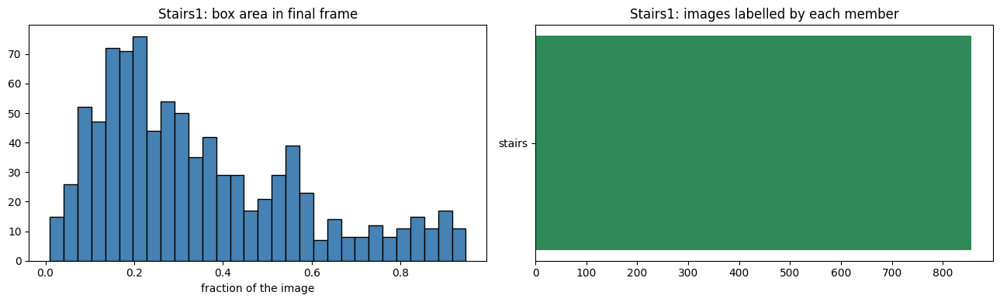

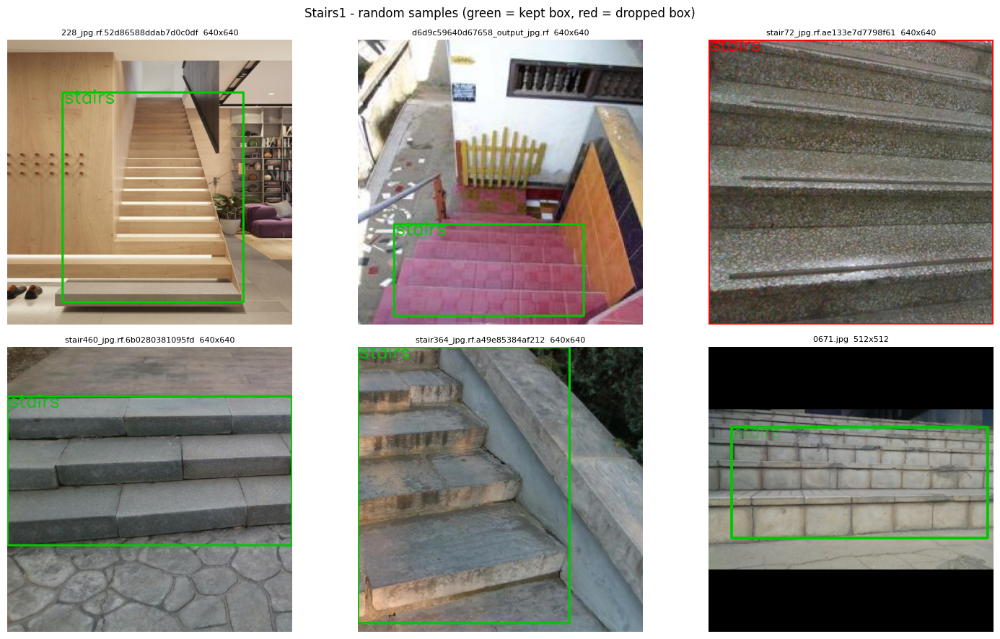

copies of the same photo (Roboflow .rf. names): 982 records -> 968 distinct photos


In [ ]:
# CELL 5a - EDA: Stairs1  (YOLO boxes; images at the folder root, labels in labels/)
recs = get_records('stairs1')   # read (or load from cache) every image + label
eda_report('Stairs1', recs)   # counts, sizes, class mapping, box statistics, sample pictures
print('copies of the same photo (Roboflow .rf. names):', len(recs), 'records ->', len({r["key"] for r in recs}), 'distinct photos')   # duplicate check


  stairs2: read 500/505

Stairs2: 505 records
status counts: {'ok': 502, 'image_without_label': 3}
image width  : 227-395 (median 227)
image height : 227-393 (median 227)
smaller than 320px on the long side (will be enlarged): 97%
with no object at all: 0

raw class name -> member -> final class        boxes
  upstair                -> stairs         -> stairs            271
  downstair              -> stairs         -> stairs            231

needed-class boxes: 502 -> 502 survive the size filters (100%)
images: 502 -> 502 keep at least one box
box area (fraction of the 320x320 frame): median 0.200, 10th pct 0.103, 90th pct 0.351

member        boxes   kept   images labelled by it
  stairs             502    502      502


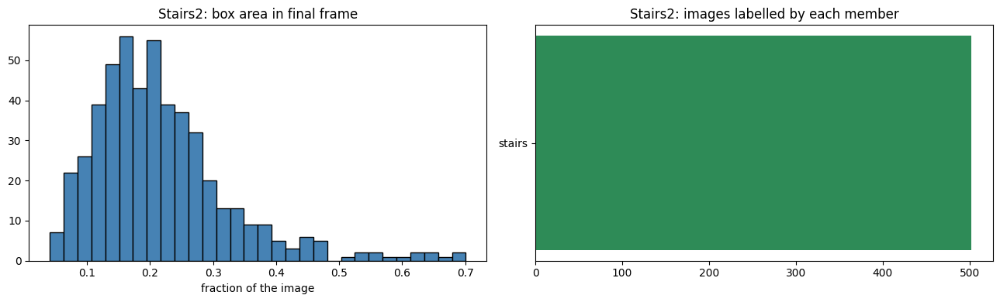

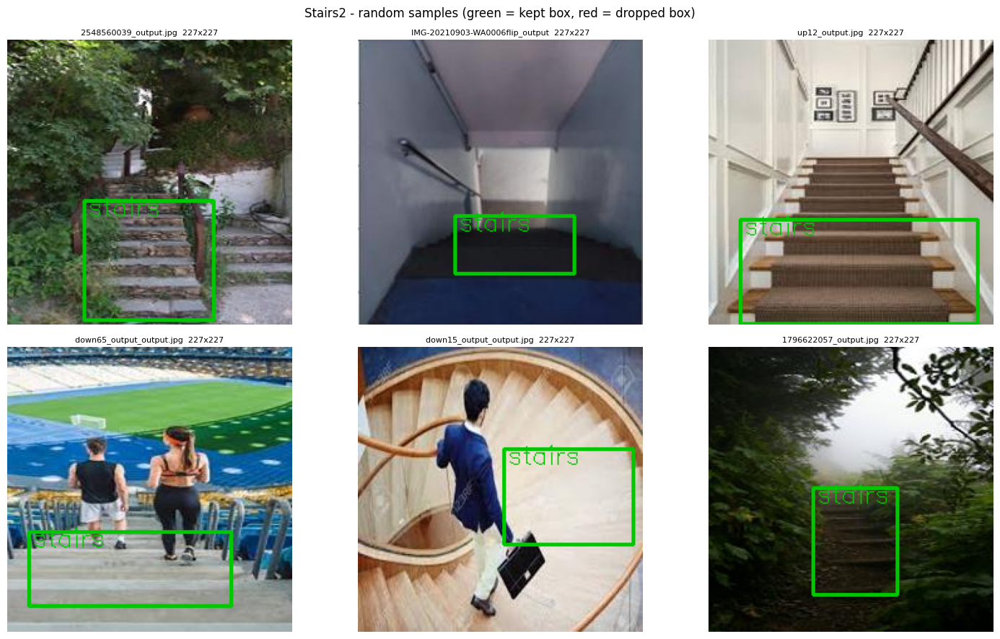

boxes rescaled because the xml size differed from the image: 0


In [ ]:
# CELL 5b - EDA: Stairs2  (Pascal-VOC xml, classes upstair/downstair, small 227x227 images)
recs = get_records('stairs2')   # read (or load from cache) every image + label
eda_report('Stairs2', recs)   # counts, sizes, class mapping, box statistics, sample pictures
print('boxes rescaled because the xml size differed from the image:', sum(1 for r in recs if r['note'] == 'rescaled'))   # how many labels needed rescaling


  pothole1: read 500/1,000
  pothole1: read 1,000/1,000

Pothhole1: 1,000 records
status counts: {'ok': 1000}
image width  : 552-640 (median 640)
image height : 347-480 (median 480)
smaller than 320px on the long side (will be enlarged): 0%
with no object at all: 4

raw class name -> member -> final class        boxes
  id0                    -> pothole        -> pothole         1,097

needed-class boxes: 1,097 -> 1,074 survive the size filters (98%)
images: 1,000 -> 996 keep at least one box
box area (fraction of the 320x320 frame): median 0.212, 10th pct 0.071, 90th pct 0.476

member        boxes   kept   images labelled by it
  pothole          1,097  1,074      996


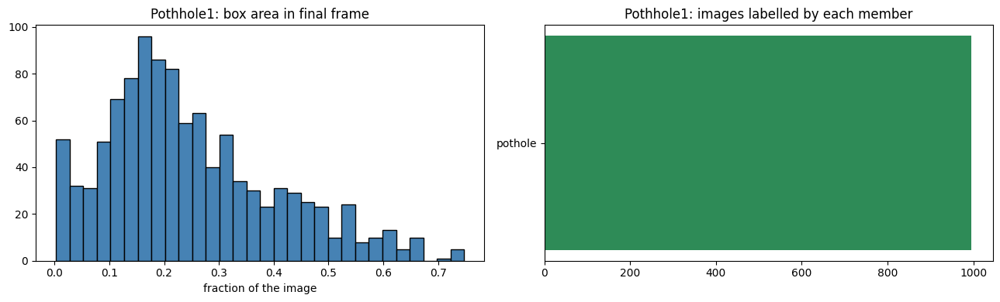

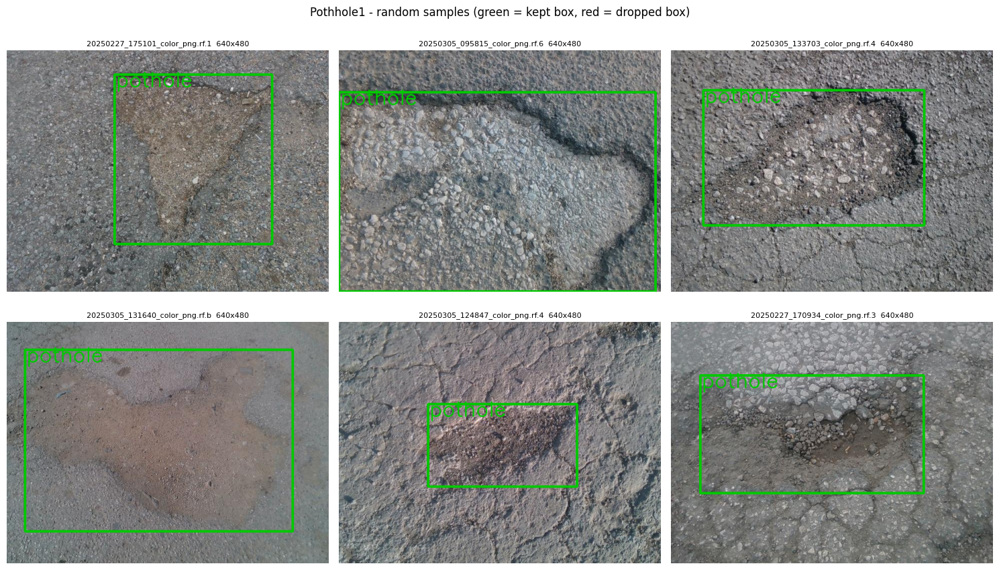

capture sessions: 21 | biggest sessions: [('pothole1:20250305_05', 131), ('pothole1:20250227_17', 103), ('pothole1:20250305_12', 97), ('pothole1:20250305_13', 97), ('pothole1:20250305_14', 68)]


In [ ]:
# CELL 5c - EDA: Pothhole1 / PothRGBD  (YOLO polygons -> we use the tight box around each polygon; depths/ is ignored)
recs = get_records('pothole1')   # read (or load from cache) every image + label
eda_report('Pothhole1', recs)   # counts, sizes, class mapping, box statistics, sample pictures
sess = Counter(session_of('pothole1', r['stem']) for r in recs)   # images per capture session (date + hour)
print('capture sessions:', len(sess), '| biggest sessions:', sess.most_common(5))   # sessions must stay in one split


  pothole2: read 500/666

Pothole2: 666 records
status counts: {'ok': 665, 'image_without_label': 1}
image width  : 300-600 (median 400)
image height : 140-533 (median 300)
smaller than 320px on the long side (will be enlarged): 1%
with no object at all: 0

raw class name -> member -> final class        boxes
  pothole                -> pothole        -> pothole         1,740

needed-class boxes: 1,740 -> 1,477 survive the size filters (85%)
images: 665 -> 662 keep at least one box
box area (fraction of the 320x320 frame): median 0.025, 10th pct 0.005, 90th pct 0.154

member        boxes   kept   images labelled by it
  pothole          1,740  1,477      662


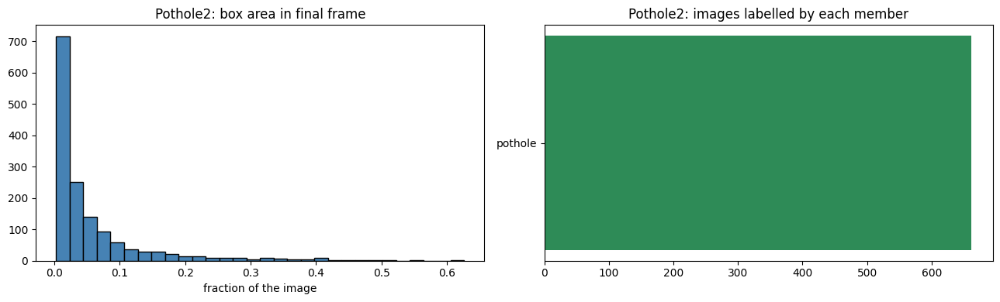

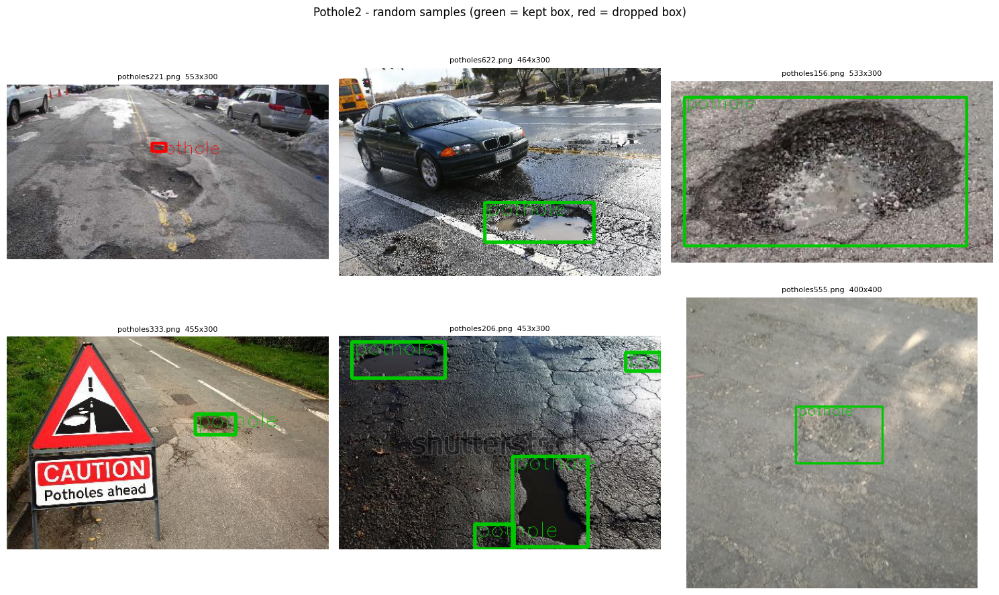

boxes rescaled because the xml size differed from the image: 0


In [ ]:
# CELL 5d - EDA: Pothole2  (Pascal-VOC xml, class pothole, PNG images of different sizes)
recs = get_records('pothole2')   # read (or load from cache) every image + label
eda_report('Pothole2', recs)   # counts, sizes, class mapping, box statistics, sample pictures
print('boxes rescaled because the xml size differed from the image:', sum(1 for r in recs if r['note'] == 'rescaled'))   # how many labels needed rescaling


  crosswalk: read 500/3,080
  crosswalk: read 1,000/3,080
  crosswalk: read 1,500/3,080
  crosswalk: read 2,000/3,080
  crosswalk: read 2,500/3,080
  crosswalk: read 3,000/3,080

Crosswalk: 3,434 records
status counts: {'ok': 3434}
image width  : 1280-1280 (median 1280)
image height : 720-720 (median 720)
smaller than 320px on the long side (will be enlarged): 0%
with no object at all: 0

raw class name -> member -> final class        boxes
  id0                    -> crosswalk      -> crosswalk       3,157
  id1                    -> None           -> (ignored)         599

needed-class boxes: 3,157 -> 2,846 survive the size filters (90%)
images: 3,434 -> 2,628 keep at least one box
box area (fraction of the 320x320 frame): median 0.051, 10th pct 0.004, 90th pct 0.147

member        boxes   kept   images labelled by it
  crosswalk        3,157  2,846    2,628


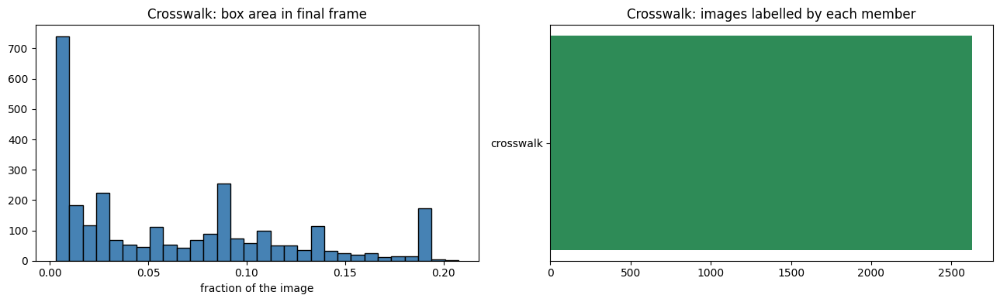

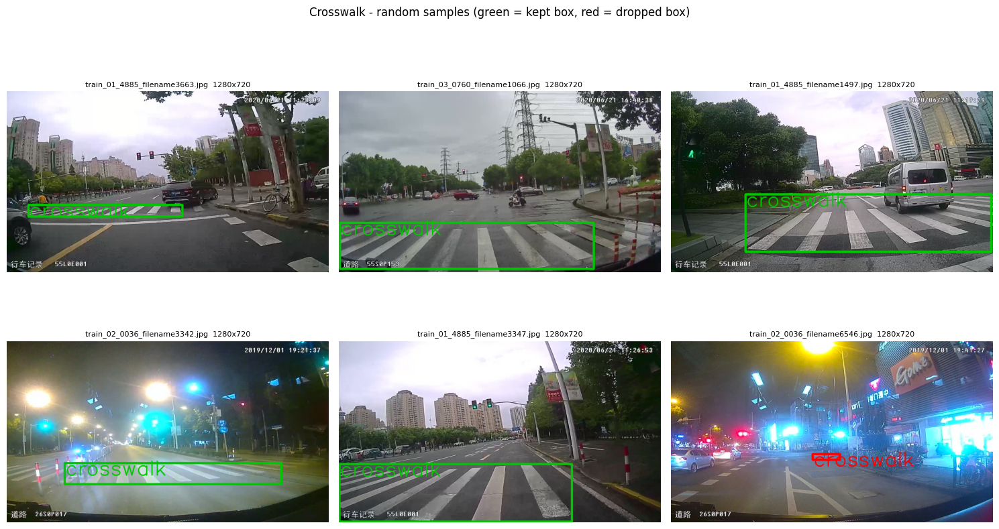

videos: {'01_4885': 756, '02_0036': 1982, '03_0760': 696}
scene blocks of 25 neighbouring frames: 276 (each block is kept inside ONE split)


In [ ]:
# CELL 5e - EDA: Crosswalk / CDSet  (YOLO boxes; id0 = crosswalk is used, id1 = guide arrows is ignored)
recs = get_records('crosswalk')   # read (or load from cache) train + test images and labels together
eda_report('Crosswalk', recs)   # counts, sizes, class mapping, box statistics, sample pictures
blocks = Counter(session_of('crosswalk', r['stem']) for r in recs)   # frames per scene block
videos = Counter(r['stem'].split('_filename')[0] for r in recs)   # frames per source video
print('videos:', dict(videos))   # the video ids found in the file names
print(f'scene blocks of {CW_BLOCK} neighbouring frames:', len(blocks), '(each block is kept inside ONE split)')   # leakage control


  doors: processed 300/1,446
  doors: processed 600/1,446
  doors: processed 900/1,446
  doors: processed 1,200/1,446
classification images: 1206 Counter({'ok': 1206})
crop match score: min 1.000, median 1.000
detection images: 240 Counter({'ok': 240})
door pixel share per mask: median 0.235, max 0.822
If the median share is above ~0.6, DOOR_MASK_VALUE in cell 0 is probably the wrong value (set it to 2).

Doors: 1,446 records
status counts: {'ok': 1446}
image width  : 480-480 (median 480)
image height : 640-640 (median 640)
smaller than 320px on the long side (will be enlarged): 0%
with no object at all: 0

raw class name -> member -> final class        boxes
  door                   -> door           -> door            1,506

needed-class boxes: 1,506 -> 1,506 survive the size filters (100%)
images: 1,446 -> 1,446 keep at least one box
box area (fraction of the 320x320 frame): median 0.347, 10th pct 0.211, 90th pct 0.483

member        boxes   kept   images labelled by it
  door      

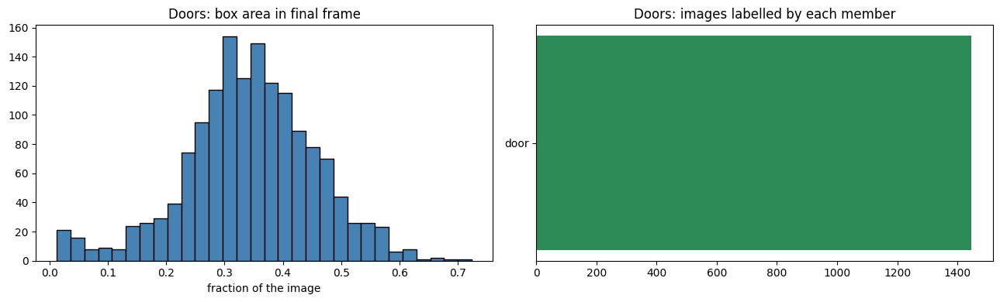

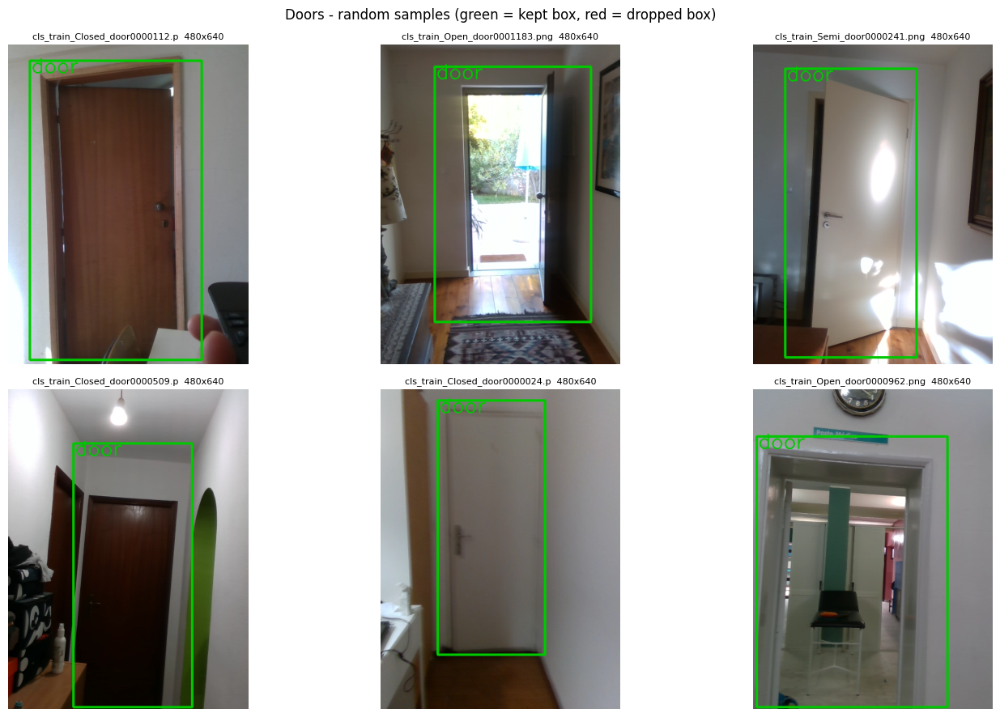

In [ ]:
# CELL 5f - EDA: Doors  (no box labels: boxes are recovered from the crops and from the masks)
recs = get_records('doors')   # read (or load from cache) every image; template-matches crops and reads masks
cls = [r for r in recs if r['note'].startswith('cls')]   # door-classification images
det = [r for r in recs if r['note'].startswith('det')]   # door-detection (mask) images
print('classification images:', len(cls), Counter(r['status'] for r in cls))   # how many boxes were recovered
scores = [float(r['note'].split('=')[1]) for r in cls if 'score=' in r['note']]   # template-match scores
print('crop match score: min %.3f, median %.3f' % (min(scores), float(np.median(scores))) if scores else 'no scores')   # ~1.0 = crop found exactly
print('detection images:', len(det), Counter(r['status'] for r in det))   # how many masks gave boxes
shares = [float(r['note'].split('=')[1]) for r in det if 'door_share=' in r['note']]   # share of door pixels per mask
print('door pixel share per mask: median %.3f, max %.3f' % (float(np.median(shares)), max(shares)) if shares else 'no masks')   # sanity check
print('If the median share is above ~0.6, DOOR_MASK_VALUE in cell 0 is probably the wrong value (set it to 2).')   # warning
eda_report('Doors', recs)   # counts, sizes, class mapping, box statistics, sample pictures



Outdoor-26classes: 32,963 records
status counts: {'ok': 32963}
image width  : 300-300 (median 300)
image height : 300-300 (median 300)
smaller than 320px on the long side (will be enlarged): 100%
with no object at all: 0

raw class name -> member -> final class        boxes
  Person                 -> person         -> person          7,369
  traffic_cone           -> traffic cone   -> object          6,152
  car                    -> car            -> car             4,734
  crosswalk              -> crosswalk      -> crosswalk       3,525
  Bushes                 -> bushes         -> vegetation      3,193
  red_light              -> traffic light  -> traffic light    3,058
  green_light            -> traffic light  -> traffic light    2,956
  bicycle                -> bicycle        -> bicycle         2,913
  elevator               -> elevator       -> door            2,910
  Bus                    -> bus            -> bus             2,679
  tree                   -> tree          

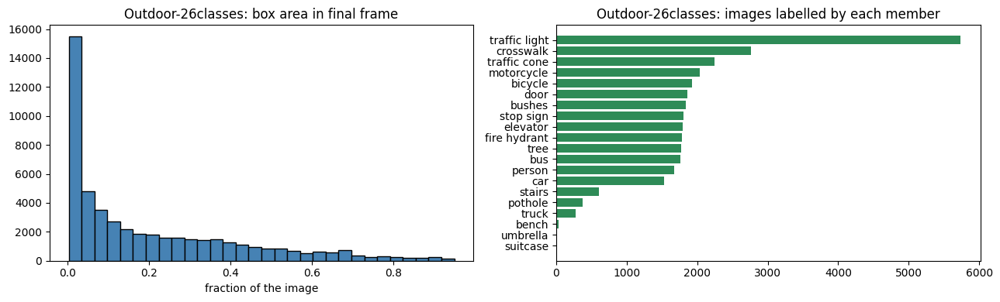

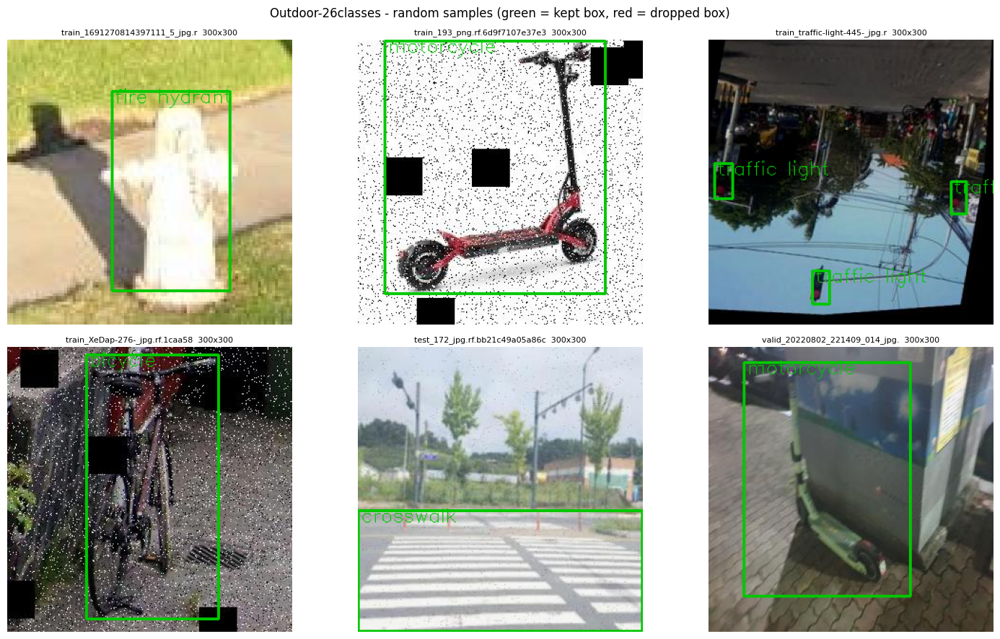

32,963 records are only 10,464 distinct photos (Roboflow augmented copies share a key)
photos found in more than one Roboflow split (a leak in the original split): 958


In [ ]:
# CELL 5g - EDA: 26classes / outdoor (Roboflow COCO json). Only images holding classes we need are analysed.
recs = get_records('outdoor')   # read (or load from cache) the annotations of train/valid/test
eda_report('Outdoor-26classes', recs)   # counts, sizes, class mapping, box statistics, sample pictures
splits_of = defaultdict(set)   # photo key -> Roboflow splits it appears in
for r in recs:   # every record
    splits_of[r['key']].add(r['note'])   # note holds the Roboflow split name
print(f'{len(recs):,} records are only {len(splits_of):,} distinct photos (Roboflow augmented copies share a key)')   # real size of the set
print('photos found in more than one Roboflow split (a leak in the original split):', sum(1 for s in splits_of.values() if len(s) > 1))   # count them



COCO: 111,785 records
status counts: {'ok': 111785}
image width  : 59-640 (median 640)
image height : 51-640 (median 480)
smaller than 320px on the long side (will be enlarged): 0%
with no object at all: 0

raw class name -> member -> final class        boxes
  person                 -> person         -> person        268,030
  car                    -> car            -> car            45,451
  chair                  -> chair          -> chair          39,844
  dining table           -> table          -> table          16,390
  traffic light          -> traffic light  -> traffic light   13,476
  handbag                -> handbag        -> object         12,882
  umbrella               -> umbrella       -> object         11,672
  bird                   -> bird           -> bird           10,969
  truck                  -> truck          -> truck          10,384
  bench                  -> bench          -> bench          10,231
  sheep                  -> sheep          -> animal      

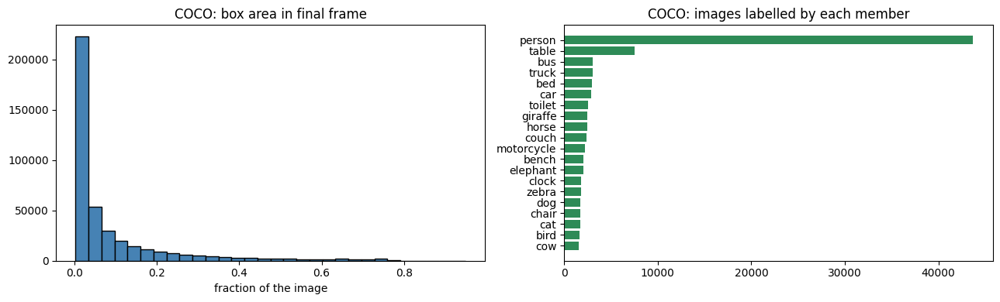

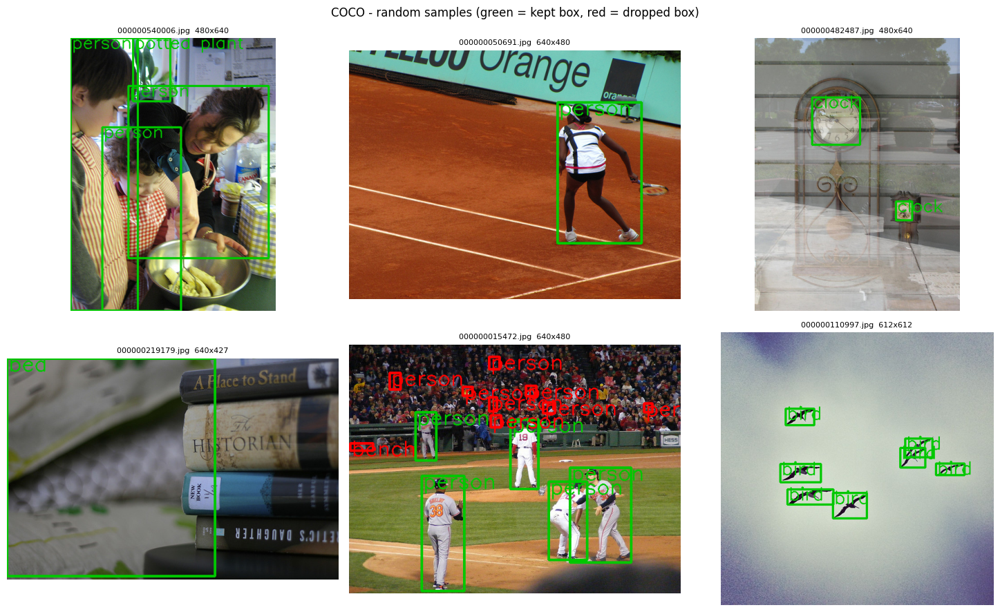

In [ ]:
# CELL 5h - EDA: COCO 2017  (train2017 + val2017). Only images holding classes we need are analysed.
recs = get_records('coco')   # read (or load from cache) the annotations; first run reads a 470 MB json
eda_report('COCO', recs)   # counts, sizes, class mapping, box statistics, sample pictures


### Combined EDA
Merges every dataset, removes duplicate photos (file-name key + perceptual hash) and shows how many independent photos each class has against the target.

  stairs1   :     856 usable images
  stairs2   :     502 usable images
  pothole1  :     996 usable images
  pothole2  :     662 usable images
  crosswalk :   2,628 usable images
  doors     :   1,446 usable images
  outdoor   :  31,849 usable images
  coco      : 107,915 usable images

Images skipped (dataset, reason): count
  coco       no valid box after filters          3,870
  outdoor    no valid box after filters          1,114
  crosswalk  no valid box after filters          806
  stairs1    no valid box after filters          80
  stairs1    label_without_image                 23
  stairs1    image_without_label                 23
  pothole1   no valid box after filters          4
  stairs2    image_without_label                 3
  pothole2   no valid box after filters          3
  pothole2   image_without_label                 1

Removing duplicate photos (this hashes about 15,000 images; the first run takes a while) ...
  hashed 1,000/17,212
  hashed 2,000/17,212
  hashed 3

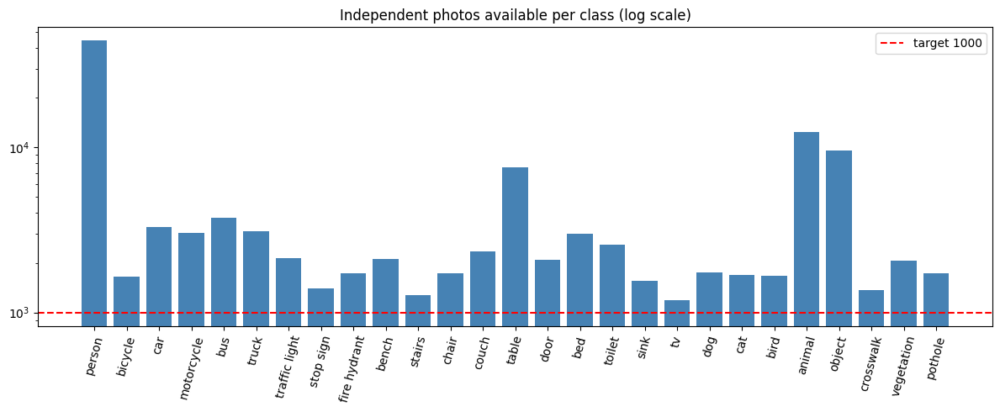

In [ ]:
# CELL 6 - COMBINED EDA: merge all datasets, remove duplicate photos, and see how many images each class can really supply.
def collect_all():   # candidates from every dataset
    cands, skipped = [], Counter()   # results
    for src in LOADERS:   # each dataset in turn
        c, s = make_candidates(get_records(src))   # records -> usable candidates
        print(f'  {src:10s}: {len(c):7,d} usable images')   # per-dataset count
        cands += c   # add to the pool
        skipped += s   # add the skip reasons
    return cands, skipped   # everything together

def dedupe_photos(cands):   # keep ONE image per photo: same file-name key OR near-identical pixels (non-COCO sets)
    by_key = defaultdict(list)   # photo key -> its copies
    for c in cands:   # every candidate
        by_key[c['key']].append(c)   # group copies of the same photo
    best = {k: max(v, key=lambda c: (len(c['boxes']), c['path'])) for k, v in by_key.items()}   # richest copy of each photo
    uf = UnionFind()   # will link photos that look identical
    for k in best:   # register every photo key
        uf.find(k)   # each starts alone
    nc = [k for k in best if best[k]['src'] != 'coco']   # COCO photos are distinct by design: hash only the others
    ph = phash_many([best[k]['path'] for k in nc])   # perceptual hash of each
    okk = [k for k in nc if ph[best[k]['path']] is not None]   # photos that could be read
    for a, b in near_dup_pairs([ph[best[k]['path']] for k in okk]):   # pairs of near-identical pictures
        uf.union(okk[a], okk[b])   # same photo found under different names
    comps = defaultdict(list)   # component root -> photo keys
    for k in best:   # every photo key
        comps[uf.find(k)].append(k)   # collect by component
    reps = []   # one representative per photo
    for root, ks in comps.items():   # each component
        rep = dict(max((best[k] for k in ks), key=lambda c: (len(c['boxes']), c['src'] != 'coco', c['path'])))   # prefer more boxes, then non-COCO
        rep['photo'] = root   # id of the photo
        rep['group'] = rep['session'] or f'p:{root}'   # split group: the scene if known, else the photo itself
        reps.append(rep)   # keep it
    return reps   # independent photos

print('Collecting candidates from all datasets ...')   # progress message
ALL, SKIPPED = collect_all()   # build every candidate
print('\nImages skipped (dataset, reason): count')   # header
for k, v in sorted(SKIPPED.items(), key=lambda kv: -kv[1])[:25]:   # the 25 most common reasons
    print(f'  {k[0]:10s} {k[1]:35s} {v:,}')   # one line each
print('\nRemoving duplicate photos (this hashes about 15,000 images; the first run takes a while) ...')   # progress message
REPS = dedupe_photos(ALL)   # independent photos
print(f'{len(ALL):,} usable images -> {len(REPS):,} independent photos')   # how much duplication there was

print(f"\n{'class':13s} {'images':>8s} {'photos':>8s} {'from COCO':>10s} {'other':>7s}   vs {TOTAL_PER_CLASS} needed")   # table header
tab = []   # rows for the chart
for cid, cname in enumerate(CLASS_LIST):   # every final class
    n_all = sum(1 for c in ALL if c['cls'] == cid)   # candidates before de-duplication
    mine = [r for r in REPS if r['cls'] == cid]   # independent photos labelled with this class
    co = sum(1 for r in mine if r['src'] == 'coco')   # of which from COCO
    flag = 'ok' if len(mine) >= TOTAL_PER_CLASS else f'SHORT by {TOTAL_PER_CLASS - len(mine):,}'   # enough or not
    print(f'{cname:13s} {n_all:8,d} {len(mine):8,d} {co:10,d} {len(mine) - co:7,d}   {flag}')   # one row per class
    tab.append((cname, len(mine)))   # for the chart
print('\nInside the merged classes (photos per member):')   # merged-class breakdown
for cname, mem in MEMBERS.items():   # each merged class
    cnt = Counter(MEMBER_LIST[r['member']] for r in REPS if r['cls'] == CLASS_ID[cname])   # photos per member
    print(f'  {cname:11s}', {m: cnt[m] for m in mem})   # show every member
plt.figure(figsize=(12, 5))   # new figure
plt.bar([t[0] for t in tab], [t[1] for t in tab], color='steelblue')   # photos per class
plt.axhline(TOTAL_PER_CLASS, color='red', ls='--', label=f'target {TOTAL_PER_CLASS}')   # target line
plt.xticks(rotation=75)   # readable labels
plt.yscale('log')   # log scale because person is huge
plt.legend()   # show the target label
plt.title('Independent photos available per class (log scale)')   # title
save_fig('availability')   # save and show


## Part C - Preprocessing
### Split (no scene shared between train / val / test)

In [ ]:
# CELL 7 - SPLIT: give every scene to train / val / test so that no scene is shared between splits.
def assign_splits(reps, seed=SEED):   # decide the split of every group (scene or photo)
    rng = random.Random(seed)   # fixed random generator
    groups = defaultdict(list)   # group id -> its images
    for r in reps:   # every independent photo
        groups[r['group']].append(r)   # collect by group
    gclasses = {g: Counter(r['cls'] for r in rs) for g, rs in groups.items()}   # classes inside each group
    N = Counter(r['cls'] for r in reps)   # photos per class
    target = {s: {} for s in ('val', 'test')}   # how many photos each class should give to val and test
    for c, n in N.items():   # every class
        for s in ('val', 'test'):   # the two held-out splits
            frac = round(SPLIT_FRAC[s] * n)   # 10% of the class
            target[s][c] = max(QUOTA[s], frac) if n >= TOTAL_PER_CLASS else frac   # at least the quota when the class is big enough
    split_of, cnt = {}, {s: Counter() for s in ('val', 'test')}   # chosen splits and running counts
    for c in sorted(N, key=lambda k: N[k]):   # rarest classes first, so they get their share
        todo = sorted(g for g in groups if g not in split_of and c in gclasses[g])   # undecided groups containing this class
        rng.shuffle(todo)   # random order
        for g in todo:   # each group
            n_c = gclasses[g][c]   # how many images of class c it holds
            for s in ('test', 'val'):   # try the held-out splits first
                if cnt[s][c] < target[s][c] and cnt[s][c] + n_c <= max(1, int(target[s][c] * 1.5)):   # needs more, and does not overshoot much
                    split_of[g] = s   # assign the whole group
                    for cc, k in gclasses[g].items():   # update the counts of every class in it
                        cnt[s][cc] += k   # add them
                    break   # decided
            else:   # no held-out split took it
                split_of[g] = 'train'   # it goes to training
    for r in reps:   # write the decision into every image
        r['split'] = split_of[r['group']]   # train / val / test

assign_splits(REPS)   # run the split
print(f"{'class':13s} {'train':>7s} {'val':>6s} {'test':>6s}   train quota {QUOTA['train']}, val {QUOTA['val']}, test {QUOTA['test']}")   # header
short = []   # classes that cannot fill a quota
for cid, cname in enumerate(CLASS_LIST):   # every class
    n = {s: sum(1 for r in REPS if r['cls'] == cid and r['split'] == s) for s in ('train', 'val', 'test')}   # photos per split
    bad = [s for s in n if n[s] < QUOTA[s]]   # splits below their quota
    if bad:   # something is short
        short.append((cname, {s: QUOTA[s] - n[s] for s in bad}))   # remember by how much
    print(f"{cname:13s} {n['train']:7,d} {n['val']:6,d} {n['test']:6,d}   " + ('ok' if not bad else 'SHORT ' + str({s: QUOTA[s] - n[s] for s in bad})))   # one row per class
print('\nClasses that cannot reach the quota with the current data:', short or 'none')   # summary
grp_split = defaultdict(set)   # group -> splits (must be exactly one each)
for r in REPS:   # every image
    grp_split[r['group']].add(r['split'])   # note its split
print('groups in more than one split (must be 0):', sum(1 for s in grp_split.values() if len(s) > 1))   # leakage check


class           train    val   test   train quota 800, val 100, test 100
person         35,516  4,440  4,440   ok
bicycle         1,324    165    165   ok
car             2,636    330    330   ok
motorcycle      2,414    302    302   ok
bus             2,983    373    373   ok
truck           2,492    311    311   ok
traffic light   1,714    214    214   ok
stop sign       1,117    140    140   ok
fire hydrant    1,387    173    173   ok
bench           1,682    210    210   ok
stairs          1,020    127    127   ok
chair           1,388    174    174   ok
couch           1,877    234    234   ok
table           6,044    755    755   ok
door            1,662    211    213   ok
bed             2,403    300    300   ok
toilet          2,048    256    256   ok
sink            1,242    155    155   ok
tv                948    118    118   ok
dog             1,403    176    176   ok
cat             1,349    169    169   ok
bird            1,332    167    167   ok
animal          9,955  1,

### Build the final dataset
Writes `final_dataset/<split>/<class>/image.jpg + image.txt` on local disk. Merged classes are balanced between their members.

In [ ]:
# CELL 8 - BUILD THE FINAL DATASET: picks QUOTA images per class and split, balances the members of merged classes,
# letterboxes to 320x320, writes image + label into  final_dataset/<split>/<class>/  (resume-safe: just run it again).
class HashBank:   # remembers the hash of every accepted image so near-duplicates are never added twice (any class, any split)
    def __init__(self):   # start empty
        self.a = np.zeros(1 << 15, dtype=np.uint64)   # storage for hashes
        self.n = 0   # how many are stored
    def add(self, h):   # store one hash
        if self.n == len(self.a):   # storage full
            self.a = np.concatenate([self.a, np.zeros(len(self.a), dtype=np.uint64)])   # double it
        self.a[self.n] = np.uint64(h)   # write the hash
        self.n += 1   # one more stored
    def near(self, h):   # is there an accepted image within PHASH_T bits of h?
        return self.n > 0 and bool((popcount64(self.a[:self.n] ^ np.uint64(h)) <= PHASH_T).any())   # compare with all stored hashes

BANK = HashBank()   # shared by all splits

def prepare(c):   # decode, check, hash and letterbox one candidate -> (candidate, jpeg bytes or None, hash, reject reason)
    try:   # reading may fail
        img = read_img(c['path'])   # decode the image
    except Exception:   # Drive or file error
        return c, None, None, 'unreadable (I/O)'   # reject
    if img is None:   # decoder returned nothing
        return c, None, None, 'unreadable'   # reject
    if (img.shape[1], img.shape[0]) != (c['w'], c['h']):   # size differs from what the labels assumed
        return c, None, None, 'size mismatch'   # reject
    ok, why = quality_ok(img)   # brightness / contrast / size check
    if not ok:   # failed the quality filter
        return c, None, None, why   # reject with the reason
    h = phash_img(img)   # perceptual hash of the original picture
    okj, buf = cv2.imencode('.jpg', letterbox(img), [cv2.IMWRITE_JPEG_QUALITY, 95])   # letterbox + JPEG quality 95
    return (c, buf.tobytes(), h, '') if okj else (c, None, None, 'encode failed')   # return the bytes or reject

def label_text(boxes):   # YOLO label text: class cx cy w h (the member id is dropped)
    return '\n'.join(f'{b[0]} {b[1]:.6f} {b[2]:.6f} {b[3]:.6f} {b[4]:.6f}' for b in boxes)   # one line per box

def interleave(a, b):   # a0 b0 a1 b1 ... (so both lists are used evenly; the longer one fills the rest)
    out, i, j = [], 0, 0   # result and two cursors
    while i < len(a) or j < len(b):   # until both are used up
        if i < len(a):   # take from a
            out.append(a[i]); i += 1   # advance a
        if j < len(b):   # take from b
            out.append(b[j]); j += 1   # advance b
    return out   # merged order

def class_dir(split, cid):   # folder of one class in one split
    return Path(FINAL_LOCAL) / split / folder_name(CLASS_LIST[cid])   # final_dataset/<split>/<class>

def build_class(split, cid, ex):   # fill one class folder; returns (rows, rejects)
    cname, out = CLASS_LIST[cid], class_dir(split, cid)   # names and folder
    shutil.rmtree(out, ignore_errors=True)   # remove any half-finished earlier attempt
    out.mkdir(parents=True)   # fresh folder
    pool = [r for r in REPS if r['split'] == split and r['cls'] == cid]   # photos allowed in this class and split
    queues = {}   # member -> ordered candidates
    for m in MEMBERS.get(cname, [cname]):   # every member of the class
        mine = [r for r in pool if MEMBER_LIST[r['member']] == m]   # photos whose label comes from this member
        mine.sort(key=lambda r: r['stem'])   # fixed order before shuffling (reproducible)
        rr = random.Random(f'{SEED}-{split}-{m}')   # reproducible shuffle
        a = [r for r in mine if r['src'] != 'coco']   # in-domain photos from the other datasets
        b = [r for r in mine if r['src'] == 'coco']   # COCO photos
        rr.shuffle(a); rr.shuffle(b)   # random order inside each list
        queues[m] = deque(interleave(a, b))   # alternate between the two
    order = list(queues)   # fixed member order (tie-break)
    rows, got, rejects, quota = [], Counter(), Counter(), QUOTA[split]   # state
    while len(rows) < quota and any(queues.values()):   # until the quota is met or the candidates run out
        batch = []   # candidates to read in parallel
        sim = Counter(got)   # member counts as if the batch were accepted
        while len(batch) < min(48, quota - len(rows)):   # fill one batch
            live = [m for m in order if queues[m]]   # members that still have candidates
            if not live:   # nothing left anywhere
                break   # stop filling
            m = min(live, key=lambda k: sim[k])   # always take from the member with the fewest accepted -> balanced
            batch.append((m, queues[m].popleft()))   # take its next candidate
            sim[m] += 1   # count it
        for (m, c), (_, data, h, why) in zip(batch, ex.map(prepare, [c for _, c in batch])):   # read the batch in parallel
            if len(rows) >= quota:   # quota reached inside the batch
                break   # ignore the surplus
            if data is None:   # candidate was rejected
                rejects[why] += 1   # count the reason
                continue   # next one
            if BANK.near(h):   # looks like an image we already accepted (any split / class)
                rejects['near-duplicate'] += 1   # count it
                continue   # next one
            (out / f"{c['stem']}.jpg").write_bytes(data)   # write the letterboxed image
            (out / f"{c['stem']}.txt").write_text(label_text(c['boxes']))   # write its YOLO label
            BANK.add(h)   # remember its hash
            got[m] += 1   # count it for its member
            rows.append(dict(split=split, cls=cname, member=m, src=c['src'], file=f"{c['stem']}.jpg", group=c['group'], hash=str(h)))   # manifest row
    (out / '_meta.json').write_text(json.dumps(dict(rows=rows, rejects=dict(rejects), quota=quota)))   # marks the class as finished
    return rows, rejects   # results

def restore_finished():   # after a restart: reload the hashes of class folders that are already finished
    n = 0   # finished folders found
    for split in ('test', 'val', 'train'):   # every split
        for cid in range(NC):   # every class
            mp = class_dir(split, cid) / '_meta.json'   # the finished-marker
            if mp.exists():   # folder is complete
                n += 1   # count it
                for row in json.loads(mp.read_text())['rows']:   # each image of it
                    BANK.add(int(row['hash']))   # restore its hash
    return n   # number of finished folders

print('already finished class folders restored:', restore_finished())   # resume support
t0 = time.time()   # timer
with ThreadPoolExecutor(WORKERS) as ex:   # parallel image reading
    for split in ('test', 'val', 'train'):   # smallest splits first, and test is protected from duplicates first
        print(f'\n=== {split} (quota {QUOTA[split]} per class) ===')   # header
        for cid in range(NC):   # every class
            if (class_dir(split, cid) / '_meta.json').exists():   # finished earlier
                continue   # skip it
            rows, rej = build_class(split, cid, ex)   # build it
            ms = Counter(r['member'] for r in rows)   # members used
            note = '' if len(rows) >= QUOTA[split] else '   <-- SHORT'   # flag a shortfall
            print(f"  {CLASS_LIST[cid]:13s} {len(rows):4d}/{QUOTA[split]}  " + (str(dict(ms)) if len(ms) > 1 else '') + note   # count and members
                  + (f"  rejected: {dict(rej)}" if rej else ''))   # and the rejection reasons
print(f'\nbuild finished in {(time.time() - t0) / 60:.1f} min')   # total time


already finished class folders restored: 0

=== test (quota 100 per class) ===
  person         100/100  
  bicycle        100/100    rejected: {'too dark': 1}
  car            100/100  
  motorcycle     100/100    rejected: {'too dark': 1}
  bus            100/100  
  truck          100/100  
  traffic light  100/100  
  stop sign      100/100  
  fire hydrant   100/100  
  bench          100/100  
  stairs         100/100  
  chair          100/100  
  couch          100/100  
  table          100/100  
  door           100/100  {'door': 50, 'elevator': 50}
  bed            100/100  
  toilet         100/100  
  sink           100/100  
  tv             100/100  
  dog            100/100  
  cat            100/100  
  bird           100/100  
  animal         100/100  {'horse': 15, 'cow': 15, 'sheep': 14, 'elephant': 14, 'bear': 14, 'zebra': 14, 'giraffe': 14}
  object         100/100  {'backpack': 10, 'handbag': 9, 'umbrella': 9, 'laptop': 9, 'refrigerator': 9, 'oven': 9, 'microwave

### Save to Drive

In [ ]:
# CELL 9b - REPAIR (run after cell 8, before cell 9): removes near-identical pictures that sit in DIFFERENT splits.
# The copy in the lower-priority split is removed (priority: test > val > train) and replaced by another image of the same class/member.
REPAIR_T = 4   # two final pictures in different splits whose hashes differ in <= this many bits count as the same scene
APPLY = True   # False = only report what would change; True = remove and replace
PRIORITY = {'test': 0, 'val': 1, 'train': 2}   # a smaller number is protected first

def hash_file(p):   # perceptual hash of a final image file
    return phash_img(cv2.imread(str(p)))   # decode it and hash it

items = []   # every final image: (split, class id, path, hash)
for s in ('test', 'val', 'train'):   # every split
    for cid in range(NC):   # every class
        for p in sorted(class_dir(s, cid).glob('*.jpg')):   # every image of that class folder
            items.append((s, cid, p, hash_file(p)))   # remember it with its hash
print(len(items), 'final images hashed')   # progress message
H = np.array([it[3] for it in items], dtype=np.uint64)   # all hashes as an array
drop = {}   # index of an image to remove -> index of the image it duplicates
for i in range(len(H) - 1):   # compare each image with all later ones
    d = popcount64(H[i + 1:] ^ H[i])   # number of differing bits
    for k in (np.nonzero(d <= REPAIR_T)[0] + i + 1):   # pictures that are very close
        k = int(k)   # plain integer index
        if items[i][0] == items[k][0]:   # same split: harmless
            continue   # ignore it
        loser = i if PRIORITY[items[i][0]] > PRIORITY[items[k][0]] else k   # the one in the lower-priority split
        drop[loser] = k if loser == i else i   # remember what it duplicates
print(f'cross-split near-duplicates at distance <= {REPAIR_T}: {len(drop)} image(s) to replace')   # how many
for j, keeper in sorted(drop.items()):   # list them
    a, b = items[j], items[keeper]   # the removed and the kept image
    print(f'  remove {a[0]}/{CLASS_LIST[a[1]]}/{a[2].name}   (duplicates {b[0]}/{CLASS_LIST[b[1]]}/{b[2].name})')   # one line per pair

if APPLY and drop:   # only change files when asked to
    meta, need = {}, defaultdict(list)   # folder metadata and the members that need a replacement
    for j in sorted(drop):   # every image to remove
        s, cid, p, _ = items[j]   # its split, class and path
        key = (s, cid)   # which class folder
        if key not in meta:   # load that folder's metadata once
            meta[key] = json.loads((class_dir(s, cid) / '_meta.json').read_text())   # parsed json
        row = next(r for r in meta[key]['rows'] if r['file'] == p.name)   # the manifest row of this image
        need[key].append(row['member'])   # remember which member to replace
        meta[key]['rows'] = [r for r in meta[key]['rows'] if r['file'] != p.name]   # drop the row
        p.unlink(); p.with_suffix('.txt').unlink()   # delete the image and its label
    Hs = [items[i][3] for i in range(len(items)) if i not in drop]   # hashes of the images that remain
    added = 0   # replacements written
    for (s, cid), members in need.items():   # every affected class folder
        cname = CLASS_LIST[cid]   # class name
        used = {r['file'][:-4] for r in meta[(s, cid)]['rows']} | {items[j][2].stem for j in drop if items[j][:2] == (s, cid)}   # stems already used or just removed
        qs = {}   # member -> shuffled unused candidates
        for m in MEMBERS.get(cname, [cname]):   # every member of the class
            mine = sorted((r for r in REPS if r['split'] == s and r['cls'] == cid and MEMBER_LIST[r['member']] == m and r['stem'] not in used), key=lambda r: r['stem'])   # fixed order
            random.Random(f'{SEED}-repair-{s}-{m}').shuffle(mine)   # reproducible shuffle
            qs[m] = deque(mine)   # queue of candidates
        for m in members:   # one replacement per removed image
            done = False   # found a replacement yet?
            for mm in [m] + [x for x in qs if x != m]:   # same member first, then the others
                while qs[mm] and not done:   # try candidates one by one
                    c = qs[mm].popleft()   # next candidate
                    _, data, h, why = prepare(c)   # read, check and letterbox it
                    if data is None or BANK.near(h):   # unreadable, poor quality, or a duplicate of an accepted image
                        continue   # try the next one
                    fh = phash_img(cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR))   # hash of the final picture
                    if (popcount64(np.array(Hs, dtype=np.uint64) ^ np.uint64(fh)) <= REPAIR_T).any():   # too similar to an image that stays
                        continue   # try the next one
                    (class_dir(s, cid) / f"{c['stem']}.jpg").write_bytes(data)   # write the image
                    (class_dir(s, cid) / f"{c['stem']}.txt").write_text(label_text(c['boxes']))   # write its label
                    BANK.add(h); Hs.append(fh)   # remember its hashes
                    meta[(s, cid)]['rows'].append(dict(split=s, cls=cname, member=MEMBER_LIST[c['member']], src=c['src'], file=f"{c['stem']}.jpg", group=c['group'], hash=str(h)))   # manifest row
                    added += 1; done = True   # one replacement written
                if done:   # stop looking
                    break   # next removed image
            if not done:   # no candidate was left
                print(f'  WARNING: could not refill {s}/{cname}')   # tell the user
    for (s, cid), m in meta.items():   # save the updated metadata of every touched folder
        (class_dir(s, cid) / '_meta.json').write_text(json.dumps(m))   # rewrite it
    print(f'removed {len(drop)} image(s), added {added} replacement(s). Now run cell 9 (save) and cell 10 (verify) again.')   # summary
elif not drop:   # nothing to repair
    print('nothing to repair')   # all clear
else:   # dry run
    print('dry run only: set APPLY = True at the top of this cell and run it again to apply the repair')   # next step

27000 final images hashed
cross-split near-duplicates at distance <= 4: 7 image(s) to replace
  remove train/chair/coco_000000146078_584d3b.jpg   (duplicates val/chair/coco_000000512576_519bdd.jpg)
  remove train/door/doors_cls_train_Closed_door0000516_8cc071.jpg   (duplicates val/door/doors_cls_train_Closed_door0000521_24b94f.jpg)
  remove train/crosswalk/crosswalk_train_01_4885_filename1025_33e406.jpg   (duplicates test/crosswalk/crosswalk_train_03_0760_filename0868_aa953c.jpg)
  remove train/crosswalk/crosswalk_train_01_4885_filename1230_da81bc.jpg   (duplicates test/crosswalk/crosswalk_train_03_0760_filename0868_aa953c.jpg)
  remove train/crosswalk/crosswalk_train_01_4885_filename1231_466483.jpg   (duplicates test/crosswalk/crosswalk_train_03_0760_filename0868_aa953c.jpg)
  remove train/crosswalk/crosswalk_train_02_0036_filename0267_3726e8.jpg   (duplicates test/crosswalk/crosswalk_train_02_0036_filename2850_aaaded.jpg)
  remove train/crosswalk/crosswalk_train_03_0760_filename3070_

In [ ]:
# CELL 9 - SAVE: manifest + class list, then copy to Drive as a normal folder AND as one .tar archive.
rows = []   # every image of the final dataset
for split in ('train', 'val', 'test'):   # every split
    for cid in range(NC):   # every class
        mp = class_dir(split, cid) / '_meta.json'   # that folder's metadata
        if mp.exists():   # finished folder
            rows += json.loads(mp.read_text())['rows']   # collect its rows
with open(f'{FINAL_LOCAL}/manifest.csv', 'w', newline='') as f:   # the table of all images
    w = csv.DictWriter(f, fieldnames=['split', 'cls', 'member', 'src', 'file', 'group', 'hash'])   # column names
    w.writeheader()   # header row
    w.writerows(rows)   # one row per image
with open(f'{FINAL_LOCAL}/classes.txt', 'w') as f:   # id -> class name
    f.write('\n'.join(f'{i} {n}' for i, n in enumerate(CLASS_LIST)))   # one line per class
json.dump(dict(classes=CLASS_LIST, members=MEMBERS, size=SIZE, quota=QUOTA, total_per_class=TOTAL_PER_CLASS,   # settings used
               filters=dict(min_area=MIN_AREA, max_area=MAX_AREA, min_side=MIN_SIDE), seed=SEED),   # box filters and seed
          open(f'{FINAL_LOCAL}/dataset_info.json', 'w'), indent=1)   # save settings next to the data
print(f'manifest: {len(rows):,} images')   # how many images were written

def copy_tree(src, dst):   # copy a folder to Drive file by file (resume-safe: files already there are skipped)
    files = [p for p in Path(src).rglob('*') if p.is_file()]   # every file
    done = failed = 0   # counters
    for i, p in enumerate(files, 1):   # each file
        q = Path(dst) / p.relative_to(src)   # destination path
        if q.exists() and q.stat().st_size == p.stat().st_size:   # already copied
            continue   # skip it
        try:   # Drive may fail
            retry(lambda: (q.parent.mkdir(parents=True, exist_ok=True), shutil.copyfile(p, q)))   # copy with retries
            done += 1   # count it
        except OSError:   # still failing after retries
            failed += 1   # count it
        if i % 2000 == 0:   # progress
            print(f'  {i:,}/{len(files):,}  copied {done:,}  failed {failed}')   # show it
    print(f'copy finished: {done:,} copied, {failed} failed (run again if failed > 0)')   # summary

copy_tree(FINAL_LOCAL, FINAL_DRIVE)   # normal folder on Drive
subprocess.run(['tar', '-cf', '/content/final_dataset.tar', '-C', str(Path(FINAL_LOCAL).parent), Path(FINAL_LOCAL).name], check=True)   # one archive
retry(lambda: shutil.copyfile('/content/final_dataset.tar', FINAL_TAR), tries=6, wait=10)   # copy the archive to Drive
print('Drive folder :', FINAL_DRIVE)   # where the folder is
print('Drive archive:', FINAL_TAR, f'({os.path.getsize(FINAL_TAR) / 1e9:.2f} GB)')   # where the archive is


manifest: 27,000 images
  2,000/54,084  copied 2,000  failed 0
  4,000/54,084  copied 4,000  failed 0
  6,000/54,084  copied 6,000  failed 0
  8,000/54,084  copied 8,000  failed 0
  10,000/54,084  copied 10,000  failed 0
  12,000/54,084  copied 12,000  failed 0
  14,000/54,084  copied 14,000  failed 0
  16,000/54,084  copied 16,000  failed 0
  18,000/54,084  copied 18,000  failed 0
  20,000/54,084  copied 20,000  failed 0
  22,000/54,084  copied 22,000  failed 0
  24,000/54,084  copied 24,000  failed 0
  26,000/54,084  copied 26,000  failed 0
  28,000/54,084  copied 28,000  failed 0
  30,000/54,084  copied 30,000  failed 0
  32,000/54,084  copied 32,000  failed 0
  34,000/54,084  copied 34,000  failed 0
  36,000/54,084  copied 36,000  failed 0
  38,000/54,084  copied 38,000  failed 0
  40,000/54,084  copied 40,000  failed 0
  42,000/54,084  copied 42,000  failed 0
  44,000/54,084  copied 44,000  failed 0
  46,000/54,084  copied 46,000  failed 0
  48,000/54,084  copied 48,000  failed 0


### Verify the final dataset


[1] images per class and split
class          train   val  test  total
person           800   100   100   1000
bicycle          800   100   100   1000
car              800   100   100   1000
motorcycle       800   100   100   1000
bus              800   100   100   1000
truck            800   100   100   1000
traffic light    800   100   100   1000
stop sign        800   100   100   1000
fire hydrant     800   100   100   1000
bench            800   100   100   1000
stairs           800   100   100   1000
chair            800   100   100   1000
couch            800   100   100   1000
table            800   100   100   1000
door             800   100   100   1000
bed              800   100   100   1000
toilet           800   100   100   1000
sink             800   100   100   1000
tv               800   100   100   1000
dog              800   100   100   1000
cat              800   100   100   1000
bird             800   100   100   1000
animal           800   100   100   1000
object  

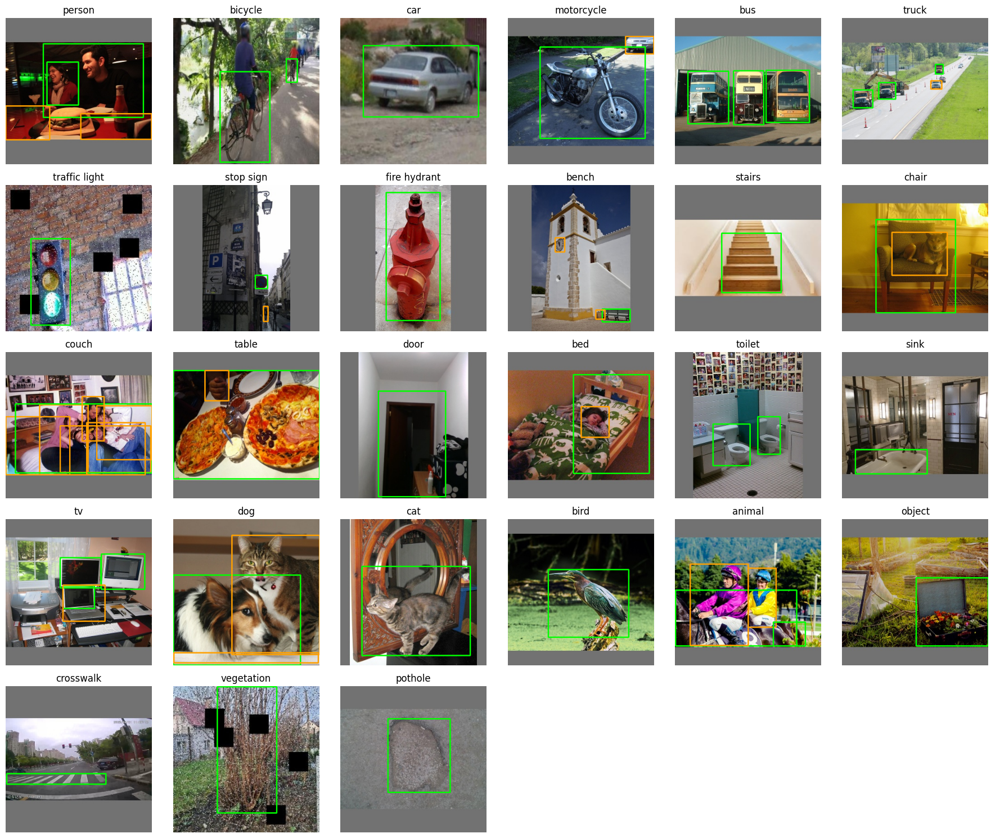


ALL CHECKS PASSED


In [ ]:
# CELL 10 - VERIFY THE FINAL DATASET: counts, balance, file/label integrity, merged-class balance, leakage, sample pictures.
ROOTV = Path(FINAL_LOCAL)   # dataset to check
if not ROOTV.exists():   # new runtime: restore the dataset from the Drive archive
    subprocess.run(['tar', '-xf', FINAL_TAR, '-C', str(ROOTV.parent)], check=True)   # unpack it
problems = []   # names of failed checks
def check(name, ok, detail=''):   # print PASS/FAIL for one check
    print(('PASS  ' if ok else 'FAIL  ') + name + (f'   {detail}' if detail else ''))   # result line
    if not ok:   # failed
        problems.append(name)   # remember it

# ---- 1. counts per class and split ----
print('\n[1] images per class and split')   # section title
cnt = {}   # (split, class) -> number of images
for s in ('train', 'val', 'test'):   # every split
    for cid, cname in enumerate(CLASS_LIST):   # every class
        cnt[(s, cname)] = len(list((ROOTV / s / folder_name(cname)).glob('*.jpg')))   # count jpg files
print(f"{'class':13s} {'train':>6s} {'val':>5s} {'test':>5s} {'total':>6s}")   # header
for cname in CLASS_LIST:   # one row per class
    t = [cnt[(s, cname)] for s in ('train', 'val', 'test')]   # counts in the three splits
    print(f'{cname:13s} {t[0]:6d} {t[1]:5d} {t[2]:5d} {sum(t):6d}' + ('' if sum(t) == TOTAL_PER_CLASS else '   <-- not ' + str(TOTAL_PER_CLASS)))   # row (flag a mismatch)
check(f'every class has exactly {TOTAL_PER_CLASS} images', all(sum(cnt[(s, c)] for s in ('train', 'val', 'test')) == TOTAL_PER_CLASS for c in CLASS_LIST))   # balance check
check('split sizes follow the quota', all(cnt[(s, c)] == QUOTA[s] for s in QUOTA for c in CLASS_LIST))   # per-split quota check
tot = {s: sum(cnt[(s, c)] for c in CLASS_LIST) for s in ('train', 'val', 'test')}   # images per split
print('images per split:', tot, '| total:', sum(tot.values()))   # totals

# ---- 2/3/4. file pairs, image integrity, label integrity (reads every file once) ----
print('\n[2-4] reading every image and label ...')   # progress message
bad_pair, bad_img, bad_lbl, not_in_label, not_largest = [], [], [], [], []   # problem lists
md5_seen, dup_md5 = {}, []   # exact-duplicate detection
hashes, hsplit = [], []   # hashes of the final images and their splits
for s in ('train', 'val', 'test'):   # every split
    for cid, cname in enumerate(CLASS_LIST):   # every class
        d = ROOTV / s / folder_name(cname)   # class folder
        for jp in sorted(d.glob('*.jpg')):   # each image
            tp = jp.with_suffix('.txt')   # its label
            if not tp.exists():   # label missing
                bad_pair.append(str(jp)); continue   # record and go on
            raw = jp.read_bytes()   # file bytes
            img = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_COLOR)   # decode the image
            if img is None or img.shape != (SIZE, SIZE, 3):   # unreadable or wrong size
                bad_img.append(str(jp)); continue   # record and go on
            md5 = hashlib.md5(raw).hexdigest()   # fingerprint of the exact file
            if md5 in md5_seen and md5_seen[md5] != s:   # same bytes already seen in another split
                dup_md5.append(str(jp))   # exact duplicate across splits
            md5_seen.setdefault(md5, s)   # remember the first split
            hashes.append(phash_img(img)); hsplit.append(s)   # hash of the final picture
            boxes, okl = [], True   # parsed boxes and validity flag
            for line in tp.read_text().splitlines():   # each label line
                v = line.split()   # fields
                try:   # numbers may be malformed
                    ok5 = len(v) == 5 and 0 <= int(v[0]) < NC and all(0 <= float(x) <= 1 for x in v[1:])   # 5 fields, valid id, coords inside 0..1
                except ValueError:   # not numeric
                    ok5 = False   # invalid
                if not ok5 or not (MIN_AREA - 1e-4 < float(v[3]) * float(v[4]) < MAX_AREA + 1e-4 and min(float(v[3]), float(v[4])) >= MIN_SIDE - 1e-4):   # bad line or box outside the size filters (tiny tolerance for 6-decimal rounding)
                    okl = False   # label invalid
                    break   # stop reading this label
                boxes.append((int(v[0]), float(v[3]) * float(v[4])))   # class id and area
            if not okl or not boxes:   # invalid or empty label
                bad_lbl.append(str(tp)); continue   # record and go on
            if cid not in {b[0] for b in boxes}:   # the folder's class is missing from its own label
                not_in_label.append(str(tp))   # record it
            elif max(boxes, key=lambda b: b[1])[0] != cid:   # largest box is another class (allowed when tree/bushes were skipped)
                not_largest.append(str(tp))   # record it for information
check('every image has a label file', not bad_pair, f'{len(bad_pair)} missing')   # pairing check
check(f'all images are readable {SIZE}x{SIZE} colour', not bad_img, f'{len(bad_img)} bad')   # integrity check
check('all labels valid (5 fields, ids and coordinates in range, boxes inside the size filters)', not bad_lbl, f'{len(bad_lbl)} bad')   # label check
check("each image's folder class appears in its label", not not_in_label, f'{len(not_in_label)} wrong')   # label/folder consistency
print(f'INFO  images whose largest box is another class (tree/bushes rule or equal boxes): {len(not_largest)} of {len(hashes):,}')   # information only

# ---- 5. merged classes: balance between members ----
print('\n[5] members inside merged classes (from manifest.csv)')   # section title
man = list(csv.DictReader(open(ROOTV / 'manifest.csv')))   # the manifest
for cname, mem in MEMBERS.items():   # each merged class
    c = Counter(r['member'] for r in man if r['cls'] == cname)   # images per member
    print(f'  {cname:11s}', {m: c[m] for m in mem})   # show them
    lo, hi = min(c[m] for m in mem), max(c[m] for m in mem)   # smallest and largest member
    print(f'              smallest member {lo}, largest {hi}  (members with fewer photos give everything they have; the others share the rest equally)')   # explain

# ---- 6. leakage ----
print('\n[6] leakage')   # section title
gs = defaultdict(set)   # group -> splits
for r in man:   # every image
    gs[r['group']].add(r['split'])   # note its split
check('no scene/photo group appears in two splits', all(len(v) == 1 for v in gs.values()), f"{sum(1 for v in gs.values() if len(v) > 1)} shared")   # group leakage
check('no byte-identical image in two splits', not dup_md5, f'{len(dup_md5)} found')   # exact duplicates
H = np.array(hashes, dtype=np.uint64)   # final-image hashes
near = 0   # near-duplicate pairs across splits
for i in range(len(H) - 1):   # compare each image with all later ones
    d = popcount64(H[i + 1:] ^ H[i])   # differing bits
    j = np.nonzero(d <= 2)[0] + i + 1   # very close pictures
    near += sum(1 for k in j if hsplit[k] != hsplit[i])   # count those in another split
check('no near-identical pictures across splits (hash distance <= 2, re-hashed from the final images)', near == 0, f'{near} pairs')   # independent leakage check

# ---- 7. sources per class ----
print('\n[7] sources per class')   # section title
srcs = sorted({r['src'] for r in man})   # dataset names present
print(f"{'class':13s} " + ' '.join(f'{s:>9s}' for s in srcs))   # header
for cname in CLASS_LIST:   # each class
    c = Counter(r['src'] for r in man if r['cls'] == cname)   # images per source
    print(f'{cname:13s} ' + ' '.join(f'{c[s]:9d}' for s in srcs))   # row

# ---- 8. pictures ----
fig, axes = plt.subplots(5, 6, figsize=(18, 15))   # grid with room for 27 classes
rr = random.Random(0)   # fixed random choice
for ax, cname in zip(axes.flatten(), CLASS_LIST):   # one picture per class
    f = rr.choice(sorted((ROOTV / 'train' / folder_name(cname)).glob('*.jpg')))   # random training image
    im = cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2RGB)   # load as RGB
    for line in f.with_suffix('.txt').read_text().splitlines():   # draw its boxes
        c, cx, cy, bw, bh = line.split(); c = int(c); cx, cy, bw, bh = (float(x) * SIZE for x in (cx, cy, bw, bh))   # parse
        cv2.rectangle(im, (int(cx - bw / 2), int(cy - bh / 2)), (int(cx + bw / 2), int(cy + bh / 2)), (0, 255, 0) if c == CLASS_ID[cname] else (255, 160, 0), 2)   # green = folder class
    ax.imshow(im); ax.set_title(cname); ax.axis('off')   # show with the class name
for ax in axes.flatten()[NC:]:   # unused cells
    ax.axis('off')   # hide them
save_fig('final_samples')   # save and show

print('\n' + '=' * 60)   # separator
print('ALL CHECKS PASSED' if not problems else f'{len(problems)} CHECK(S) FAILED: {problems}')   # final verdict


In [ ]:
import os, time, random, threading                                  # files, timing, random back-off, per-thread state
from concurrent.futures import ThreadPoolExecutor, as_completed     # run uploads in parallel
from google.colab import auth                                       # Colab's Google sign-in helper
from googleapiclient.discovery import build                         # builds the Drive API client
from googleapiclient.http import MediaFileUpload                    # file uploader

auth.authenticate_user()                                            # sign in (approve the pop-up if shown)
LOCAL = '/content/final_dataset'                                    # the verified local dataset
ROOT  = '1YwVlIN8OKXiWbWzDmBB7T1cnv9jGvVli'                         # id of the existing Drive folder final_dataset
FOLDER = 'application/vnd.google-apps.folder'                       # mime type that marks a folder
WORKERS = 8                                                         # parallel uploads (lower to 4 if Google throttles)
tl = threading.local()                                              # each thread needs its own API client

def svc():                                                          # per-thread Drive client
    if not hasattr(tl, 's'): tl.s = build('drive', 'v3', cache_discovery=False)   # build once per thread
    return tl.s                                                     # return this thread's client

def children(pid):                                                  # list everything inside a Drive folder
    out, tok = [], None                                             # collected items and page token
    while True:                                                     # loop over result pages
        r = svc().files().list(q=f"'{pid}' in parents and trashed = false", pageSize=1000,
                               fields='nextPageToken, files(id,name,mimeType)', pageToken=tok).execute()   # one page
        out += r.get('files', []); tok = r.get('nextPageToken')     # add items, get next token
        if not tok: return out                                      # done when no more pages

def get_or_create(parent, name):                                    # find a sub-folder by name or make it
    for f in children(parent):                                      # look at existing items
        if f['name'] == name and f['mimeType'] == FOLDER: return f['id']   # reuse the existing folder
    return svc().files().create(body={'name': name, 'mimeType': FOLDER, 'parents': [parent]}, fields='id').execute()['id']   # create it

def upload(path, parent):                                           # upload one file with retries
    for k in range(7):                                              # up to 7 attempts
        try:                                                        # Drive can throttle
            svc().files().create(body={'name': os.path.basename(path), 'parents': [parent]},
                                 media_body=MediaFileUpload(path, resumable=False), fields='id').execute()   # send the file
            return True                                             # success
        except Exception:                                           # rate limit or network hiccup
            time.sleep(min(60, 2 ** k) + random.random())          # wait longer each time
    return False                                                    # gave up on this file

jobs = []                                                           # (local path, Drive folder id) still to upload
for sp in ['val', 'train', 'test']:                                 # val first (smallest gap), then train
    sp_id = get_or_create(ROOT, sp)                                 # split folder in Drive
    for cls in sorted(os.listdir(f'{LOCAL}/{sp}')):                 # each class folder locally
        cid = get_or_create(sp_id, cls)                             # class folder in Drive
        have = {f['name'] for f in children(cid)}                   # file names Google already has
        for fn in sorted(os.listdir(f'{LOCAL}/{sp}/{cls}')):        # each local file
            if fn not in have: jobs.append((f'{LOCAL}/{sp}/{cls}/{fn}', cid))   # queue it if missing
print('files to upload:', len(jobs))                                # how much work is left

ok = bad = 0                                                        # success and failure counters
t0 = time.time()                                                    # start time for the rate display
with ThreadPoolExecutor(WORKERS) as ex:                             # worker pool
    futs = [ex.submit(upload, p, c) for p, c in jobs]               # submit every upload
    for i, f in enumerate(as_completed(futs), 1):                   # as each finishes
        ok += f.result(); bad += (not f.result())                   # count the result
        if i % 500 == 0:                                            # progress line
            print(f'{i:,}/{len(jobs):,}  ok {ok:,}  failed {bad}  {i / (time.time() - t0):.1f} files/s')   # speed shown
print('done. uploaded', ok, 'failed', bad, '(re-run this cell if failed > 0)')   # summary

files to upload: 37656


500/37,656  ok 500  failed 0  3.4 files/s
1,000/37,656  ok 1,000  failed 0  3.5 files/s
1,500/37,656  ok 1,500  failed 0  3.6 files/s
2,000/37,656  ok 2,000  failed 0  3.7 files/s
2,500/37,656  ok 2,500  failed 0  3.7 files/s
3,000/37,656  ok 3,000  failed 0  3.7 files/s
3,500/37,656  ok 3,500  failed 0  3.8 files/s
4,000/37,656  ok 4,000  failed 0  3.8 files/s
4,500/37,656  ok 4,500  failed 0  3.8 files/s
5,000/37,656  ok 5,000  failed 0  3.8 files/s
5,500/37,656  ok 5,500  failed 0  3.9 files/s
6,000/37,656  ok 6,000  failed 0  3.9 files/s
6,500/37,656  ok 6,500  failed 0  3.9 files/s
7,000/37,656  ok 7,000  failed 0  3.9 files/s
7,500/37,656  ok 7,500  failed 0  3.9 files/s
8,000/37,656  ok 8,000  failed 0  3.9 files/s
8,500/37,656  ok 8,500  failed 0  4.0 files/s
9,000/37,656  ok 9,000  failed 0  4.0 files/s
9,500/37,656  ok 9,500  failed 0  4.0 files/s
10,000/37,656  ok 10,000  failed 0  4.0 files/s
10,500/37,656  ok 10,500  failed 0  4.0 files/s


11,000/37,656  ok 11,000  failed 0  4.0 files/s
11,500/37,656  ok 11,500  failed 0  4.0 files/s
12,000/37,656  ok 12,000  failed 0  4.0 files/s
12,500/37,656  ok 12,500  failed 0  4.0 files/s
13,000/37,656  ok 13,000  failed 0  4.0 files/s
13,500/37,656  ok 13,500  failed 0  4.0 files/s
14,000/37,656  ok 14,000  failed 0  4.0 files/s
14,500/37,656  ok 14,500  failed 0  4.0 files/s
15,000/37,656  ok 15,000  failed 0  4.0 files/s
15,500/37,656  ok 15,500  failed 0  4.1 files/s
16,000/37,656  ok 16,000  failed 0  4.1 files/s
16,500/37,656  ok 16,500  failed 0  4.1 files/s
17,000/37,656  ok 17,000  failed 0  4.1 files/s
17,500/37,656  ok 17,500  failed 0  4.1 files/s
18,000/37,656  ok 18,000  failed 0  4.0 files/s
18,500/37,656  ok 18,500  failed 0  4.0 files/s
19,000/37,656  ok 19,000  failed 0  4.0 files/s
19,500/37,656  ok 19,500  failed 0  4.0 files/s
20,000/37,656  ok 20,000  failed 0  4.0 files/s
20,500/37,656  ok 20,500  failed 0  4.0 files/s
21,000/37,656  ok 21,000  failed 0  4.0 

24,000/37,656  ok 24,000  failed 0  3.9 files/s
24,500/37,656  ok 24,500  failed 0  3.9 files/s
25,000/37,656  ok 25,000  failed 0  3.9 files/s
25,500/37,656  ok 25,500  failed 0  3.9 files/s
26,000/37,656  ok 26,000  failed 0  3.9 files/s
26,500/37,656  ok 26,500  failed 0  3.9 files/s
27,000/37,656  ok 27,000  failed 0  3.9 files/s
27,500/37,656  ok 27,500  failed 0  3.9 files/s
28,000/37,656  ok 28,000  failed 0  3.9 files/s
28,500/37,656  ok 28,500  failed 0  3.8 files/s
29,000/37,656  ok 29,000  failed 0  3.8 files/s
29,500/37,656  ok 29,500  failed 0  3.8 files/s
30,000/37,656  ok 30,000  failed 0  3.8 files/s
30,500/37,656  ok 30,500  failed 0  3.8 files/s
31,000/37,656  ok 31,000  failed 0  3.8 files/s
31,500/37,656  ok 31,500  failed 0  3.8 files/s
32,000/37,656  ok 32,000  failed 0  3.8 files/s
32,500/37,656  ok 32,500  failed 0  3.8 files/s
33,000/37,656  ok 33,000  failed 0  3.8 files/s
33,500/37,656  ok 33,500  failed 0  3.8 files/s
34,000/37,656  ok 34,000  failed 0  3.8 

36,000/37,656  ok 36,000  failed 0  3.8 files/s
36,500/37,656  ok 36,500  failed 0  3.8 files/s
37,000/37,656  ok 37,000  failed 0  3.8 files/s
37,500/37,656  ok 37,500  failed 0  3.8 files/s
done. uploaded 37656 failed 0 (re-run this cell if failed > 0)


In [ ]:
from google.colab import auth                                       # Colab's Google sign-in helper
from googleapiclient.discovery import build                         # builds the Drive API client

auth.authenticate_user()                                            # sign in (approve the pop-up if shown)
svc = build('drive', 'v3', cache_discovery=False)                   # Drive API client
FYP_FOLDER = '1zTYmJUB7hznyDpfA_Zt2f50uYU52Pa6V'                    # id of My Drive/FYP
EXPECT = {'train': 800, 'val': 100, 'test': 100}                    # images expected per class in each split
FOLDER = 'application/vnd.google-apps.folder'                       # mime type that marks a folder

def children(pid):                                                  # list every non-trashed item inside a folder
    out, tok = [], None                                             # collected items and the page token
    while True:                                                     # loop over result pages
        r = svc.files().list(q=f"'{pid}' in parents and trashed = false", pageSize=1000,
                             fields='nextPageToken, files(id,name,mimeType)', pageToken=tok).execute()   # one page
        out += r.get('files', [])                                   # add this page's items
        tok = r.get('nextPageToken')                                # token for the next page, if any
        if not tok: return out                                      # no more pages, so return everything

cands = [f for f in children(FYP_FOLDER) if f['name'] == 'final_dataset' and f['mimeType'] == FOLDER]   # folders named final_dataset
print('final_dataset folders under FYP:', [(c['id']) for c in cands])   # normally exactly one
root = cands[0]['id']                                               # use the first one found

top = children(root)                                                # items directly inside final_dataset
print('top level:', sorted(f['name'] for f in top))                 # expect train, val, test, manifest.csv, classes.txt, dataset_info.json

grand = {'train': 0, 'val': 0, 'test': 0}                           # image totals per split
bad = []                                                            # class folders that are short or duplicated
for sp in ['train', 'val', 'test']:                                 # go through each split
    sp_f = [f for f in top if f['name'] == sp and f['mimeType'] == FOLDER]   # the split folder
    if not sp_f:                                                    # split folder missing
        print(f'{sp}: MISSING'); continue                           # report and move on
    classes = [f for f in children(sp_f[0]['id']) if f['mimeType'] == FOLDER]   # class folders in this split
    print(f'\n{sp}: {len(classes)} class folders (expected 27)')    # how many class folders arrived
    for c in sorted(classes, key=lambda x: x['name']):              # each class folder in alphabetical order
        items = children(c['id'])                                   # files inside the class folder
        names = [i['name'] for i in items]                          # their names
        n_img = sum(n.lower().endswith('.jpg') for n in names)      # image count
        n_txt = sum(n.lower().endswith('.txt') for n in names)      # label count
        n_uni = len(set(names))                                     # unique names (Drive can hold duplicates)
        flag = '' if (n_img == EXPECT[sp] and n_txt == EXPECT[sp] and n_uni == len(names)) else '  <-- CHECK'   # mark problems
        if flag: bad.append((sp, c['name'], n_img, n_txt))          # remember the problem folders
        grand[sp] += n_img                                          # add to the split total
        print(f"  {c['name']:<18} img={n_img:<4} txt={n_txt:<4} other={len(names)-n_img-n_txt}{flag}")   # one line per class

print('\nimages in Drive:', grand, ' expected:', {k: v * 27 for k, v in EXPECT.items()})   # totals versus the target
print('folders needing attention:', len(bad))                       # how many are incomplete

final_dataset folders under FYP: ['1YwVlIN8OKXiWbWzDmBB7T1cnv9jGvVli']
top level: ['classes.txt', 'dataset_info.json', 'manifest.csv', 'test', 'train', 'val']

train: 27 class folders (expected 27)
  animal             img=800  txt=800  other=1
  bed                img=800  txt=800  other=1
  bench              img=800  txt=800  other=1
  bicycle            img=800  txt=800  other=1
  bird               img=800  txt=800  other=1
  bus                img=800  txt=800  other=1
  car                img=800  txt=800  other=1
  cat                img=800  txt=800  other=1
  chair              img=800  txt=800  other=1
  couch              img=800  txt=800  other=1
  crosswalk          img=800  txt=800  other=1
  dog                img=800  txt=800  other=1
  door               img=800  txt=800  other=1
  fire_hydrant       img=800  txt=800  other=1
  motorcycle         img=800  txt=800  other=1
  object             img=800  txt=800  other=1
  person             img=800  txt=800  other=1
  p

In [ ]:
import time, random, threading                                       # timing, back-off, per-thread state
from collections import defaultdict                                  # grouping helper
from datetime import datetime, timedelta                             # to show creation times in Sri Lanka time
from concurrent.futures import ThreadPoolExecutor                    # run API calls in parallel
from google.colab import auth                                        # Colab's Google sign-in helper
from googleapiclient.discovery import build                          # builds the Drive API client

auth.authenticate_user()                                             # sign in (approve the pop-up if shown)
APPLY = True                                                        # False = only show the plan; set True to trash the older copies
ROOT = '1YwVlIN8OKXiWbWzDmBB7T1cnv9jGvVli'                           # id of the Drive folder final_dataset
FOLDER = 'application/vnd.google-apps.folder'                        # mime type that marks a folder
EXPECT = {'train': 800, 'val': 100, 'test': 100}                     # images (and labels) expected per class
tl = threading.local()                                               # each thread needs its own API client

def svc():                                                           # per-thread Drive client
    if not hasattr(tl, 's'): tl.s = build('drive', 'v3', cache_discovery=False)   # build once per thread
    return tl.s                                                      # return this thread's client

def retry(fn):                                                       # run an API call, retrying on throttling
    for k in range(6):                                               # up to 6 attempts
        try: return fn()                                             # success
        except Exception: time.sleep(min(30, 2 ** k) + random.random())   # wait longer each time
    raise RuntimeError('Drive API kept failing')                     # give up loudly

def children(pid):                                                   # every non-trashed item inside a folder, with its creation time and size
    out, tok = [], None                                              # collected items and page token
    while True:                                                      # loop over result pages
        r = retry(lambda: svc().files().list(q=f"'{pid}' in parents and trashed = false", pageSize=1000,
                  fields='nextPageToken, files(id,name,mimeType,createdTime,size)', pageToken=tok).execute())   # one page
        out += r.get('files', []); tok = r.get('nextPageToken')      # add items, get next token
        if not tok: return out                                       # done when no more pages

def is_dir(f): return f['mimeType'] == FOLDER                        # True for folders
def ist(t): return (datetime.strptime(t[:19], '%Y-%m-%dT%H:%M:%S') + timedelta(hours=5, minutes=30)).strftime('%d %b %H:%M:%S')   # UTC text -> Sri Lanka time
def newest(items): return sorted(items, key=lambda f: f['createdTime'], reverse=True)   # newest first

def complete(cid, sp):                                               # does this class folder hold the full set of unique images and labels?
    names = [i['name'] for i in children(cid) if not is_dir(i)]      # file names inside
    return len({n for n in names if n.lower().endswith('.jpg')}) == EXPECT[sp] and len({n for n in names if n.lower().endswith('.txt')}) == EXPECT[sp]   # 800/800 or 100/100

trash = []                                                           # (id, description) of everything to trash

def plan_classes(split_id, sp):                                      # duplicate class folders inside one split folder
    groups = defaultdict(list)                                       # class name -> folders with that name
    for c in children(split_id):                                     # each child
        if is_dir(c): groups[c['name']].append(c)                    # group folders by name
    kept = []                                                        # the folders that survive
    for name, fl in sorted(groups.items()):                          # each class name
        fl = newest(fl); keep = fl[0]; kept.append(keep)             # newest copy is the keeper
        if len(fl) > 1:                                              # duplicated class folder
            ok = complete(keep['id'], sp)                            # is the newest copy complete?
            print(f"  {sp}/{name}: {len(fl)} folders, keep newest ({ist(keep['createdTime'])}), older: {[ist(o['createdTime']) for o in fl[1:]]}, newest complete = {ok}")   # show the times
            if ok:                                                   # safe to remove the older ones
                trash.extend((o['id'], f'{sp}/{name} folder ({ist(o["createdTime"])})') for o in fl[1:])   # plan to trash them
            else:                                                    # newest is incomplete
                print('    SKIPPED: the newest copy is not complete, nothing trashed for this class')   # warn
    return kept                                                      # keepers for the next step

def plan_files(cid):                                                 # same-named files stored twice in one folder
    by = defaultdict(list)                                           # file name -> copies
    for f in children(cid):                                          # each item
        if not is_dir(f): by[f['name']].append(f)                    # group files by name
    n = 0                                                            # surplus copies found
    for fl in by.values():                                           # each name
        if len(fl) > 1:                                              # stored more than once
            fl.sort(key=lambda f: (int(f.get('size', 0)) > 0, f['createdTime']), reverse=True)   # newest non-empty first
            trash.extend((o['id'], 'duplicate file') for o in fl[1:]); n += len(fl) - 1   # plan to trash the older copies
    return n                                                         # how many extras

def report(title):                                                   # count what Google holds, unique files only
    print(f'\n=== {title} ===')                                      # section title
    top = children(ROOT)                                             # items directly in final_dataset
    for sp in ['train', 'val', 'test']:                              # each split
        sfs = [f for f in top if f['name'] == sp and is_dir(f)]      # folders with this split's name
        classes = [c for sf in sfs for c in children(sf['id']) if is_dir(c)]   # all class folders
        bad = [(c['name'], c['id']) for c in classes if not complete(c['id'], sp)]   # incomplete ones
        print(f'{sp}: {len(sfs)} split folder(s), {len(classes)} class folders, {len(bad)} incomplete {[b[0] for b in bad]}')   # summary

report('BEFORE')                                                     # current state

top = children(ROOT)                                                 # top level of final_dataset
print('\n--- PLAN ---')                                              # section title
for sp in ['train', 'val', 'test']:                                  # each split
    sfs = newest([f for f in top if f['name'] == sp and is_dir(f)])  # split folders newest first
    if not sfs: continue                                             # none found
    print(f'{sp}: {len(sfs)} folder(s), created (Sri Lanka time): {[ist(f["createdTime"]) for f in sfs]}')   # show the times
    keep = sfs[0]                                                    # newest split folder is the keeper
    kept = plan_classes(keep['id'], sp)                              # sort out duplicate class folders inside it
    dups = sum(plan_files(c['id']) for c in kept)                    # remove duplicate files inside the kept classes
    print(f'  {sp}: {len(kept)} classes kept, {dups} surplus duplicate files planned for trash')   # summary
    if len(sfs) > 1:                                                 # whole split folder is duplicated
        ok = len(kept) == 27 and all(complete(c['id'], sp) for c in kept)   # is the newest split folder complete?
        print(f'  newest {sp} folder complete = {ok}')                # show the check
        if ok: trash.extend((o['id'], f'whole {sp} folder ({ist(o["createdTime"])})') for o in sfs[1:])   # trash the older split folders
        else: print('  SKIPPED: the newest copy is not complete, older folders kept')   # warn
print(f'\nTotal to trash: {len(trash)} items')                       # size of the plan

if APPLY:                                                            # only change things when asked
    with ThreadPoolExecutor(8) as ex:                                # trash in parallel
        list(ex.map(lambda t: retry(lambda: svc().files().update(fileId=t[0], body={'trashed': True}, fields='id').execute()), trash))   # move each item to Trash
    report('AFTER')                                                  # final state


=== BEFORE ===


train: 1 split folder(s), 46 class folders, 0 incomplete []
val: 2 split folder(s), 54 class folders, 0 incomplete []
test: 1 split folder(s), 27 class folders, 0 incomplete []

--- PLAN ---
train: 1 folder(s), created (Sri Lanka time): ['04 Nov 20:16:00']
  train/bed: 2 folders, keep newest (04 Nov 22:32:48), older: ['04 Nov 20:20:19'], newest complete = True
  train/bench: 2 folders, keep newest (04 Nov 22:32:49), older: ['04 Nov 20:29:24'], newest complete = True
  train/bicycle: 2 folders, keep newest (04 Nov 22:32:51), older: ['04 Nov 20:25:38'], newest complete = True
  train/bird: 2 folders, keep newest (04 Nov 22:32:53), older: ['04 Nov 20:25:02'], newest complete = True
  train/car: 2 folders, keep newest (04 Nov 22:32:57), older: ['04 Nov 20:22:36'], newest complete = True
  train/chair: 2 folders, keep newest (04 Nov 22:32:59), older: ['04 Nov 20:31:30'], newest complete = True
  train/couch: 2 folders, keep newest (04 Nov 22:33:01), older: ['04 Nov 20:30:03'], newest comple

  test: 27 classes kept, 0 surplus duplicate files planned for trash

Total to trash: 1830 items



=== AFTER ===
train: 1 split folder(s), 27 class folders, 0 incomplete []
val: 1 split folder(s), 27 class folders, 0 incomplete []
test: 1 split folder(s), 27 class folders, 0 incomplete []
